# Solar filament image preprocessing

Native-resolution MAGFiLO preprocessing for the 2026 segmentation challenge.
Run the notebook in order. The default run inspects **six training images**, compares
their candidates with the supplied COCO annotations, and saves a preview cache.
After inspecting these results, enable `RUN_FULL_EXPORT` to cache train/validation;
add `"test"` to `EXPORT_SPLITS` when the settings are fixed.

**Image branch:** validate grayscale -> detect/mask solar disk -> 3 x 3 median ->
radial limb-darkening correction -> degree-3 polynomial background correction ->
CLAHE (2.0, 8 x 8) -> robust percentile normalization.

**Auxiliary branch:** signed Laplacian -> 20 adaptive threshold intervals ->
8-connected candidates -> area filtering -> optional conservative closing.
The candidate branch never replaces the enhanced image. It is an image-derived
feature, **not a ground-truth mask**. Closing is disabled initially to avoid joining
separate instances.

The three input alternatives are **A:** original grayscale; **B:** enhanced grayscale;
**C:** `[original, enhanced, candidates]` stored in RGB channel order. No source image
is resized, cropped, rotated, or warped. Downsampling is used only for disk detection,
background fitting, and preview selection.


## 1. Imports and settings

Dependencies: `numpy opencv-python pillow matplotlib pandas tqdm pycocotools`.
If needed, install them in the notebook's environment before running these cells.
No GPU or model package is required. Paths are discovered locally or under
`/kaggle/input`; override `INPUT_DIR` if necessary.


In [30]:
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
import copy
import hashlib
import json
import math
import os
import platform
import re
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
from pycocotools import mask as coco_mask

# Each image is independent; avoid OpenCV threads competing with image workers.
cv2.setNumThreads(8)
PIPELINE_VERSION = "solar-filament-preprocessing-v3"
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
ANNOTATION_NAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

In [31]:
def discover_input_dir():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    for base in candidates:
        for root in (base, base / "MAGFilo_1.0_Kaggle_2026"):
            if (root / "train" / ANNOTATION_NAME).is_file():
                return root
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        found = sorted(kaggle.rglob(ANNOTATION_NAME))
        if len(found) == 1:
            return found[0].parent.parent
    raise FileNotFoundError("Set INPUT_DIR to the MAGFilo_1.0_Kaggle_2026 directory.")


INPUT_DIR = discover_input_dir()
OUTPUT_DIR = (
    Path("/kaggle/working/solar_preprocessed")
    if Path("/kaggle/input").exists()
    else INPUT_DIR.parent / "Final" / "processed_images" / "solar_preprocessed"
)
SEED = 42
VAL_FRACTION = 0.20
PREVIEW_COUNT = 6  # 5-10 recommended; training images only
WORKERS = min(8, os.cpu_count() or 1)  # bounded memory, including at 2048 x 2048
RUN_FULL_EXPORT = True  # inspect previews and metrics first
EXPORT_SPLITS = ("train", "val")  # add 'test' after freezing preprocessing

# All these parameters are image-local. There is no dataset-wide fit and no label input.
CONFIG = {
    "expected_shape": [2048, 2048],
    "strict_shape": True,
    "hough_coarse_size": 512,
    "hough_fine_size": 1024,
    "hough_param1": 80.0,
    "hough_param2": 35.0,
    "disk_radius_fraction": [
        0.25,
        0.49,
    ],  # full disk must fit inside the frame; excludes outer halo
    "median_kernel": 3,
    "radial_bins": 128,
    "radial_sample_stride": 4,
    "radial_gain_limits": [0.5, 2.5],
    "polynomial_degree": 3,
    "polynomial_sample_stride": 16,
    "polynomial_clip_sigma": 3.0,
    "polynomial_iterations": 3,
    "clahe_clip_limit": 2.0,
    "clahe_grid": [8, 8],
    "normalization_percentiles": [1.0, 99.5],
    "threshold_intervals": 20,
    "threshold_sigma_span": 3.0,
    "threshold_edge": "upper",  # include the scored interval; 'lower' reproduces Yuan's edge rule
    "candidate_limb_margin_px": 2,
    "min_component_area_px": 16,
    "min_component_disk_fraction": 1e-5,
    "closing_kernel": 0,  # 0 = off; try 3 only after checking merge errors
    "save_intermediates": True,
    "save_float_stages": True,  # compressed, lossless NumPy intermediate arrays
}

print("Input:", INPUT_DIR)
print("Output:", OUTPUT_DIR)
print(
    "Full export:", RUN_FULL_EXPORT, "| splits:", EXPORT_SPLITS, "| workers:", WORKERS
)

Input: D:\filament-segmentation-2026\MAGFilo_1.0_Kaggle_2026
Output: D:\filament-segmentation-2026\Final\processed_images\solar_preprocessed
Full export: True | splits: ('train', 'val') | workers: 8


## 2. Discover files and freeze a split before preprocessing

The provided COCO file can contain **multiple image IDs for one filename**. We
process each physical image once, retain every corresponding image ID, and group
all observations from the same calendar date into one split. Filenames and available
image metadata determine the split; masks and categories do not. The persisted
manifest is reused on reruns and refuses a changed input inventory or split settings.
To deliberately create a new experiment, use a new `OUTPUT_DIR`.

Only supplied training images enter train/validation; test files remain separate.
Images are loaded one at a time rather than retaining the entire dataset in RAM.


In [32]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(
        json.dumps(payload, indent=2, allow_nan=False), encoding="utf-8"
    )
    temporary.replace(path)


def digest(payload):
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def find_image_files(directory):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"Image directory does not exist: {directory}")
    return sorted(
        p
        for p in directory.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )


def date_group(name, image_rows=()):
    match = re.match(r"(\d{8})", Path(name).name)
    if match:
        return match.group(1)
    dates = {
        str(row.get("date_captured", ""))[:10].replace("-", "")
        for row in image_rows
        if row.get("date_captured")
    }
    if len(dates) == 1:
        return dates.pop()
    raise ValueError(
        f"Cannot assign one observation date to {name}; define its date group."
    )


def discover_records(input_dir, coco):
    input_dir = Path(input_dir)
    rows_by_name = defaultdict(list)
    ids = set()
    for row in coco["images"]:
        if row["id"] in ids:
            raise ValueError(f"Duplicate COCO image id: {row['id']}")
        ids.add(row["id"])
        rows_by_name[Path(row["file_name"]).name].append(row)
    records = []
    for source_split in ("train", "test"):
        paths = find_image_files(input_dir / source_split)
        seen_names, seen_stems = set(), set()
        for path in paths:
            if path.name in seen_names or path.stem in seen_stems:
                raise ValueError(
                    f"Ambiguous output filename in {source_split}: {path.name}"
                )
            seen_names.add(path.name)
            seen_stems.add(path.stem)
            rows = rows_by_name.get(path.name, []) if source_split == "train" else []
            if source_split == "train" and not rows:
                raise ValueError(
                    f"No COCO image metadata for training file {path.name}"
                )
            shapes = {(int(r["height"]), int(r["width"])) for r in rows}
            if len(shapes) > 1:
                raise ValueError(f"Conflicting image dimensions for {path.name}")
            records.append(
                {
                    "source": path.relative_to(input_dir).as_posix(),
                    "name": path.name,
                    "output_name": path.stem + ".png",
                    "source_split": source_split,
                    "group": (
                        date_group(path.name, rows) if source_split == "train" else None
                    ),
                    "image_ids": [r["id"] for r in rows],
                    "coco_shape": list(next(iter(shapes))) if shapes else None,
                }
            )
    train_names = {r["name"] for r in records if r["source_split"] == "train"}
    test_names = {r["name"] for r in records if r["source_split"] == "test"}
    if train_names & test_names:
        raise ValueError(
            "Train and test share source filenames; resolve the overlap first."
        )
    if not train_names:
        raise ValueError("No training images found.")
    return records


def make_split_manifest(records, seed, val_fraction):
    if not 0 < val_fraction < 1:
        raise ValueError("VAL_FRACTION must be between zero and one.")
    groups = sorted({r["group"] for r in records if r["source_split"] == "train"})
    if len(groups) < 2:
        raise ValueError(
            "At least two observation dates are needed for a held-out split."
        )
    shuffled = np.random.default_rng(seed).permutation(groups)
    n_val = max(1, min(len(groups) - 1, round(len(groups) * val_fraction)))
    val_groups = set(shuffled[:n_val])
    result = []
    for record in records:
        split = (
            "test"
            if record["source_split"] == "test"
            else "val" if record["group"] in val_groups else "train"
        )
        result.append(dict(record, split=split))
    return {
        "seed": seed,
        "val_fraction": val_fraction,
        "inventory_sha256": digest(records),
        "records": result,
    }


def freeze_manifest(records, path, seed, val_fraction):
    proposed = make_split_manifest(records, seed, val_fraction)
    path = Path(path)
    if path.exists():
        existing = read_json(path)
        if existing != proposed:
            raise ValueError(
                "Saved split differs from current data/settings. Use a new OUTPUT_DIR."
            )
        return existing
    write_json(path, proposed)
    return proposed


def load_grayscale(path, cfg, coco_shape=None):
    # Check the source dtype rather than silently truncating a 16-bit image to uint8.
    with Image.open(path) as image:
        image.verify()
    with Image.open(path) as image:
        array = np.asarray(image)
        if array.dtype != np.uint8:
            raise ValueError(f"{path}: expected uint8 source, got {array.dtype}")
        gray = np.asarray(image.convert("L")).copy()
    if gray.ndim != 2 or not gray.size or not np.isfinite(gray).all():
        raise ValueError(f"{path}: expected a nonempty, finite 2-D image")
    if cfg["strict_shape"] and tuple(gray.shape) != tuple(cfg["expected_shape"]):
        raise ValueError(f'{path}: expected {cfg["expected_shape"]}, got {gray.shape}')
    if coco_shape and tuple(gray.shape) != tuple(coco_shape):
        raise ValueError(f"{path}: source shape disagrees with COCO metadata")
    return np.ascontiguousarray(gray)

In [33]:
ANNOTATION_PATH = INPUT_DIR / "train" / ANNOTATION_NAME
COCO = read_json(ANNOTATION_PATH)
records = discover_records(INPUT_DIR, COCO)
manifest = freeze_manifest(
    records, OUTPUT_DIR / "split_manifest.json", SEED, VAL_FRACTION
)
records = manifest["records"]
annotations_by_image = defaultdict(list)
for annotation in COCO["annotations"]:
    annotations_by_image[annotation["image_id"]].append(annotation)
image_rows_by_id = {row["id"]: row for row in COCO["images"]}

split_summary = pd.DataFrame(
    [
        {
            "split": split,
            "physical_images": sum(r["split"] == split for r in records),
            "coco_image_ids": sum(
                len(r["image_ids"]) for r in records if r["split"] == split
            ),
            "observation_dates": len(
                {
                    r["group"]
                    for r in records
                    if r["split"] == split and r["group"] is not None
                }
            ),
        }
        for split in ("train", "val", "test")
    ]
)
display(split_summary)
assert {r["group"] for r in records if r["split"] == "train"}.isdisjoint(
    {r["group"] for r in records if r["split"] == "val"}
)

,split,physical_images,coco_image_ids,observation_dates
0,train,562,905,525
1,val,145,249,131
2,test,180,0,0


## 3. Solar disk detection and masking

Use a coarse Hough search, then a finer search with a restricted radius. Circle
geometry is mapped back to the original pixel grid. The radius search excludes
frame-touching outer halos and requires the detected full disk to fit inside the
source frame. A validated Otsu-contour
ellipse is a logged fallback if Hough fails; a failed detection raises an error
instead of silently applying an arbitrary central disk. The mask covers the full
detected disk; candidate extraction excludes a configurable two-pixel limb margin
to avoid a false Laplacian response at the mask boundary.


In [34]:
def resize_for_detection(image, long_side):
    scale = min(1.0, long_side / max(image.shape))
    size = (
        max(1, round(image.shape[1] * scale)),
        max(1, round(image.shape[0] * scale)),
    )
    small = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
    # Separate scale factors account for integer rounding on non-square inputs.
    return small, np.array([size[0] / image.shape[1], size[1] / image.shape[0]])


def valid_circle(cx, cy, radius, shape, cfg):
    h, w = shape
    lo, hi = cfg["disk_radius_fraction"]
    return (
        lo * min(h, w) <= radius <= hi * min(h, w)
        and abs(cx - (w - 1) / 2) < 0.20 * w
        and abs(cy - (h - 1) / 2) < 0.20 * h
        and cx - radius >= 0
        and cx + radius < w
        and cy - radius >= 0
        and cy + radius < h
    )


def detect_solar_disk(image, cfg):
    if float(np.std(image)) < 1:
        raise ValueError("Solar disk detection failed: image has almost no contrast.")
    coarse, scale = resize_for_detection(image, cfg["hough_coarse_size"])
    blur = cv2.medianBlur(coarse, 5)
    lo, hi = cfg["disk_radius_fraction"]
    circles = cv2.HoughCircles(
        blur,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=min(blur.shape) / 2,
        param1=cfg["hough_param1"],
        param2=cfg["hough_param2"],
        minRadius=round(lo * min(blur.shape)),
        maxRadius=round(hi * min(blur.shape)),
    )
    disk = None
    if circles is not None:
        for cx, cy, radius in circles[0]:
            values = (
                float(cx / scale[0]),
                float(cy / scale[1]),
                float(radius / scale.mean()),
            )
            if valid_circle(*values, image.shape, cfg):
                disk = dict(zip(("cx", "cy", "radius"), values), method="hough-coarse")
                break
    if disk is None:
        _, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if contours:
            contour = max(contours, key=cv2.contourArea)
            if len(contour) >= 20 and cv2.contourArea(contour) > 0.15 * blur.size:
                (cx, cy), (a, b), _ = cv2.fitEllipse(contour)
                values = (
                    float(cx / scale[0]),
                    float(cy / scale[1]),
                    float((a + b) / (4 * scale.mean())),
                )
                if min(a, b) / max(a, b) > 0.90 and valid_circle(
                    *values, image.shape, cfg
                ):
                    disk = dict(
                        zip(("cx", "cy", "radius"), values), method="contour-fallback"
                    )
    if disk is None:
        raise ValueError(
            "No plausible solar disk found; inspect image/detection settings."
        )

    if disk["method"].startswith("hough"):
        fine, fs = resize_for_detection(image, cfg["hough_fine_size"])
        r = disk["radius"] * fs.mean()
        tolerance = max(4, 0.025 * r)
        refined = cv2.HoughCircles(
            cv2.medianBlur(fine, 5),
            cv2.HOUGH_GRADIENT,
            dp=1.2,
            minDist=min(fine.shape) / 2,
            param1=cfg["hough_param1"],
            param2=cfg["hough_param2"],
            minRadius=max(1, round(r - tolerance)),
            maxRadius=round(r + tolerance),
        )
        if refined is not None:
            for cx, cy, radius in refined[0]:
                values = (
                    float(cx / fs[0]),
                    float(cy / fs[1]),
                    float(radius / fs.mean()),
                )
                displacement = math.hypot(
                    values[0] - disk["cx"], values[1] - disk["cy"]
                )
                if displacement < 0.04 * disk["radius"] and valid_circle(
                    *values, image.shape, cfg
                ):
                    disk = dict(
                        zip(("cx", "cy", "radius"), values),
                        method="hough-coarse-to-fine",
                    )
                    break
    yy, xx = np.ogrid[: image.shape[0], : image.shape[1]]
    rho = (np.hypot(xx - disk["cx"], yy - disk["cy"]) / disk["radius"]).astype(
        np.float32
    )
    mask = rho <= 1.0
    if np.median(image[mask]) <= np.median(image[~mask]) + 5:
        raise ValueError(
            "Detected disk is not brighter than space; inspect this image."
        )
    return disk, rho, mask

## 4. Median filtering, limb darkening, background correction, CLAHE

Estimate a smooth radial median profile without labels. Cap radial gains to prevent
amplification near the limb. Fit a third-degree 2-D polynomial to sampled on-disk
pixels with iterative residual clipping to reduce the influence of filaments and
bright active regions; subtract its spatial variation while preserving the median.
CLAHE operates on a robustly scaled uint8 view, then percentile normalization produces
the final enhanced image. Normalization statistics are calculated **per image inside
the disk**, using the same procedure for every split. Constant ranges are handled
explicitly. Float correction fields remain available for inspection/export.


In [35]:
def robust_unit(image, mask, percentiles):
    values = np.asarray(image)[mask]
    if not values.size or not np.isfinite(values).all():
        raise ValueError("Normalization requires finite on-disk pixels.")
    low, high = np.percentile(values, percentiles)
    result = np.zeros(image.shape, np.float32)
    if high - low <= 1e-6:
        result[mask] = 0.5
    else:
        result[mask] = np.clip((image[mask] - low) / (high - low), 0, 1)
    return result, {"low": float(low), "high": float(high)}


def to_uint8(unit):
    return np.rint(np.clip(unit, 0, 1) * 255).astype(np.uint8)


def radial_correction(image, rho, disk_mask, cfg):
    stride = cfg["radial_sample_stride"]
    radii = rho[::stride, ::stride]
    intensities = image[::stride, ::stride].astype(np.float32)
    bins = cfg["radial_bins"]
    centers = (np.arange(bins) + 0.5) / bins
    profile = np.full(bins, np.nan, np.float32)
    for i in range(bins):
        pixels = intensities[(radii >= i / bins) & (radii < (i + 1) / bins)]
        if pixels.size >= 4:
            profile[i] = np.median(pixels)
    good = np.isfinite(profile) & (profile > 1)
    if good.sum() < max(4, bins // 4):
        raise ValueError(
            "Insufficient radial samples; adjust radial sampling settings."
        )
    profile = np.interp(centers, centers[good], profile[good]).astype(np.float32)
    profile = cv2.GaussianBlur(profile[None, :], (9, 1), 0).ravel()
    target = float(np.median(profile[centers < 0.5]))
    background = (
        np.interp(rho.ravel(), centers, profile).reshape(image.shape).astype(np.float32)
    )
    gain = np.clip(target / np.maximum(background, 1), *cfg["radial_gain_limits"])
    corrected = image.astype(np.float32) * gain
    corrected[~disk_mask] = 0
    return corrected, centers, profile


def polynomial_correction(image, disk_mask, disk, cfg):
    yy, xx = np.ogrid[: image.shape[0], : image.shape[1]]
    x = ((xx - disk["cx"]) / disk["radius"]).astype(np.float32)
    y = ((yy - disk["cy"]) / disk["radius"]).astype(np.float32)
    stride = cfg["polynomial_sample_stride"]
    sampled_mask = disk_mask[::stride, ::stride]
    xs = np.broadcast_to(x[:, ::stride], sampled_mask.shape)[sampled_mask]
    ys = np.broadcast_to(y[::stride, :], sampled_mask.shape)[sampled_mask]
    values = image[::stride, ::stride][sampled_mask].astype(np.float64)
    degree = cfg["polynomial_degree"]
    powers = [
        (i, j)
        for total in range(degree + 1)
        for i in range(total + 1)
        for j in [total - i]
    ]
    design = np.column_stack([xs**i * ys**j for i, j in powers]).astype(np.float64)
    low, high = np.percentile(values, [10, 90])
    keep = (values >= low) & (values <= high)
    coefficients = None
    for _ in range(cfg["polynomial_iterations"]):
        if keep.sum() < 3 * len(powers):
            raise ValueError("Insufficient pixels for polynomial background fit.")
        coefficients, _, rank, _ = np.linalg.lstsq(
            design[keep], values[keep], rcond=None
        )
        if rank != len(powers):
            raise ValueError("Polynomial background fit is rank deficient.")
        residual = values - design @ coefficients
        center = np.median(residual[keep])
        mad = max(1.4826 * np.median(np.abs(residual[keep] - center)), 1e-3)
        keep = np.abs(residual - center) <= cfg["polynomial_clip_sigma"] * mad
    background = np.zeros(image.shape, np.float32)
    for coefficient, (i, j) in zip(coefficients, powers):
        background += np.float32(coefficient) * (x**i) * (y**j)
    target = float(np.median(background[disk_mask]))
    corrected = image - background + target
    corrected[~disk_mask] = 0
    background[~disk_mask] = 0
    return corrected.astype(np.float32), background, coefficients.tolist()


def enhance_image(corrected, disk_mask, cfg):
    unit, before_stats = robust_unit(
        corrected, disk_mask, cfg["normalization_percentiles"]
    )
    clahe_input = to_uint8(unit)
    # Neutral off-disk fill limits black-space influence in edge CLAHE tiles.
    clahe_input[~disk_mask] = int(np.median(clahe_input[disk_mask]))
    clahe = cv2.createCLAHE(
        clipLimit=cfg["clahe_clip_limit"], tileGridSize=tuple(cfg["clahe_grid"])
    ).apply(clahe_input)
    clahe[~disk_mask] = 0
    normalized, after_stats = robust_unit(
        clahe, disk_mask, cfg["normalization_percentiles"]
    )
    return (
        clahe,
        to_uint8(normalized),
        {"pre_clahe": before_stats, "post_clahe": after_stats},
    )

## 5. Auxiliary Laplacian and adaptive candidate detection

Yuan (2011), _Development of advanced algorithms to detect, characterize and
forecast solar activities_, section 2.3.2 (printed pp. 35-36; local PDF pp. 55-56),
uses the signed kernel below, with **positive response at dark structures**:

```text
 1   1   1
 1  -8   1
 1   1   1
```

On the enhanced image scaled to [0, 1], construct 20 equal intervals from
`median - 3 * std` to `median`. For interval `[T_i, T_(i+1))`, compute the mean
signed response of **newly included pixels**. Select the interval with maximum
mean response. By default use its **upper edge** `T_(i+1)`, including the pixels
that supplied the evidence. This is an explicit adaptation: the source uses the
lower edge `T_i`. With the added percentile clipping, that lower edge can be
negative and produce an empty mask even when the scored interval contains dark
filaments. Set `threshold_edge = 'lower'` to reproduce that part of the source
exactly. Skip empty intervals; return no candidates if no positive evidence is available.
The threshold is image-specific and does not use any annotation.

This adapts the source's candidate-selection rule to the requested CLAHE and
normalization, with a small limb exclusion and optional rather than mandatory closing.
The defaults are experimental starting points, not established optimal MAGFiLO values.


In [36]:
LAPLACIAN_KERNEL = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float32)


def adaptive_candidates(enhanced, disk_mask, cfg):
    unit = enhanced.astype(np.float32) / 255.0
    laplacian = cv2.filter2D(
        unit, cv2.CV_32F, LAPLACIAN_KERNEL, borderType=cv2.BORDER_REFLECT_101
    )
    margin = int(cfg["candidate_limb_margin_px"])
    if margin < 0:
        raise ValueError("Candidate limb margin cannot be negative.")
    eligible = (
        cv2.erode(
            disk_mask.astype(np.uint8), np.ones((3, 3), np.uint8), iterations=margin
        ).astype(bool)
        if margin
        else disk_mask.copy()
    )
    laplacian[~eligible] = 0
    values = unit[eligible]
    if not values.size:
        raise ValueError("Candidate mask has no interior pixels.")
    median, std = float(np.median(values)), float(np.std(values))
    intervals = int(cfg["threshold_intervals"])
    if intervals < 2:
        raise ValueError("Use at least two threshold intervals.")
    if cfg["threshold_edge"] not in ("lower", "upper"):
        raise ValueError("threshold_edge must be lower or upper.")
    edges = np.linspace(
        median - cfg["threshold_sigma_span"] * std, median, intervals + 1
    )
    scores = np.full(intervals, np.nan)
    counts = np.zeros(intervals, np.int64)
    responses = laplacian[eligible]
    for i, (low, high) in enumerate(zip(edges[:-1], edges[1:])):
        included = (values >= low) & (values < high)
        counts[i] = included.sum()
        if counts[i]:
            scores[i] = float(np.mean(responses[included]))
    selected = None
    raw = np.zeros(enhanced.shape, bool)
    if std > 1e-6 and np.isfinite(scores).any():
        best = int(np.nanargmax(scores))
        if scores[best] > 0:
            selected = float(edges[best + (cfg["threshold_edge"] == "upper")])
            raw = eligible & (unit < selected)
    diagnostics = {
        "median": median,
        "std": std,
        "threshold": selected,
        "threshold_edge": cfg["threshold_edge"],
        "edges": edges.tolist(),
        "counts": counts.tolist(),
        "mean_laplacian": [float(s) if np.isfinite(s) else None for s in scores],
    }
    return laplacian, eligible, raw, diagnostics


def filter_components(mask, disk_area, cfg):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )
    minimum = max(
        int(cfg["min_component_area_px"]),
        math.ceil(disk_area * cfg["min_component_disk_fraction"]),
    )
    keep = stats[:, cv2.CC_STAT_AREA] >= minimum
    keep[0] = False
    result = keep[labels]
    return result, {
        "minimum_area_px": minimum,
        "raw_components": count - 1,
        "filtered_components": int(keep.sum()),
    }


def conservative_closing(mask, eligible, cfg):
    size = int(cfg["closing_kernel"])
    if size == 0:
        return mask.copy()
    if size != 3:
        raise ValueError("Conservative closing supports 0 (off) or 3 (one iteration).")
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    return (
        cv2.morphologyEx(
            mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel, iterations=1
        ).astype(bool)
        & eligible
    )


def preprocess_image(image, cfg):
    if image.dtype != np.uint8 or image.ndim != 2:
        raise ValueError("preprocess_image expects a 2-D uint8 grayscale array.")
    started = time.perf_counter()
    disk, rho, disk_mask = detect_solar_disk(image, cfg)
    masked = np.where(disk_mask, image, 0).astype(np.uint8)
    median = cv2.medianBlur(image, cfg["median_kernel"])
    median[~disk_mask] = 0
    radial, radial_centers, radial_profile = radial_correction(
        median, rho, disk_mask, cfg
    )
    corrected, background, coefficients = polynomial_correction(
        radial, disk_mask, disk, cfg
    )
    clahe, enhanced, normalization = enhance_image(corrected, disk_mask, cfg)
    laplacian, eligible, raw, thresholds = adaptive_candidates(enhanced, disk_mask, cfg)
    filtered, components = filter_components(raw, int(disk_mask.sum()), cfg)
    candidates = conservative_closing(filtered, eligible, cfg)
    multi_channel = np.stack(
        [image, enhanced, candidates.astype(np.uint8) * 255], axis=-1
    )
    return {
        "original": image.copy(),
        "disk_mask": disk_mask,
        "masked": masked,
        "median": median,
        "radial": radial,
        "background": background,
        "corrected": corrected,
        "clahe": clahe,
        "enhanced": enhanced,
        "laplacian": laplacian,
        "raw_candidates": raw,
        "filtered_candidates": filtered,
        "candidates": candidates,
        "multi_channel": multi_channel,
        "metadata": {
            "disk": disk,
            "shape": list(image.shape),
            "radial_centers": radial_centers.tolist(),
            "radial_profile": radial_profile.tolist(),
            "polynomial_coefficients": coefficients,
            "normalization": normalization,
            "threshold_selection": thresholds,
            "components": components,
            "preprocessing_seconds": time.perf_counter() - started,
        },
    }

## 6. Inspect every stage on representative training images

Choose contrast quantiles of small grayscale thumbnails from the training split,
without consulting labels. Full-resolution processing and export use the original
images. Each image produces a 15-panel diagnostic and a radial/threshold plot.
The enhanced image and candidate feature are shown separately. Inspect thin
filament continuity, the solar limb, noise, and unwanted connections before tuning.


In [37]:
def select_preview_records(records, input_dir, count):
    training = [r for r in records if r["split"] == "train"]
    ranked, errors = [], []
    for record in training:
        try:
            with Image.open(Path(input_dir) / record["source"]) as image:
                thumb = image.convert("L")
                thumb.thumbnail((128, 128))
                array = np.asarray(thumb)
            on_disk = array[array > max(10, float(np.percentile(array, 30)))]
            if not on_disk.size:
                raise ValueError("Empty foreground in preview thumbnail")
            contrast = float(np.percentile(on_disk, 90) - np.percentile(on_disk, 10))
            ranked.append((contrast, record["source"], record))
        except Exception as exc:
            errors.append({"source": record["source"], "error": str(exc)})
    if not ranked:
        raise ValueError(f"No readable training previews. Errors: {errors[:3]}")
    ranked.sort(key=lambda row: row[:2])
    indices = np.unique(
        np.linspace(0, len(ranked) - 1, min(count, len(ranked))).round().astype(int)
    )
    return [ranked[i][2] for i in indices], errors


def signed_laplacian_view(laplacian, disk_mask):
    limit = max(float(np.percentile(np.abs(laplacian[disk_mask]), 99)), 1e-6)
    view = to_uint8(0.5 + 0.5 * laplacian / limit)
    view[~disk_mask] = 0
    return view


def show_stages(record, result, cfg):
    mask = result["disk_mask"]
    disk = result["metadata"]["disk"]
    outlined = cv2.cvtColor(result["original"], cv2.COLOR_GRAY2RGB)
    cv2.circle(
        outlined,
        (round(disk["cx"]), round(disk["cy"])),
        round(disk["radius"]),
        (255, 100, 40),
        max(1, result["original"].shape[0] // 700),
    )

    def scaled(key):
        return to_uint8(
            robust_unit(result[key], mask, cfg["normalization_percentiles"])[0]
        )

    panels = [
        ("1 Original", result["original"]),
        ("2 Detected disk", outlined),
        ("3 Disk mask", mask),
        ("4 Masked", result["masked"]),
        ("5 Median 3 x 3", result["median"]),
        ("6 Radial corrected", scaled("radial")),
        ("7 Polynomial background", scaled("background")),
        ("8 Corrected", scaled("corrected")),
        ("9 CLAHE", result["clahe"]),
        ("10 Normalized enhanced", result["enhanced"]),
        ("11 Signed Laplacian", signed_laplacian_view(result["laplacian"], mask)),
        ("12 Threshold candidates", result["raw_candidates"]),
        ("13 Area filtered", result["filtered_candidates"]),
        ("14 Final candidates", result["candidates"]),
        ("15 Three-channel RGB", result["multi_channel"]),
    ]
    fig, axes = plt.subplots(3, 5, figsize=(18, 11), constrained_layout=True)
    for ax, (title, array) in zip(axes.flat, panels):
        ax.imshow(array, cmap="gray", vmin=0, vmax=1 if array.dtype == bool else 255)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    fig.suptitle(
        f"{record['name']} | {disk['method']} | "
        f"{result['metadata']['preprocessing_seconds']:.2f} s",
        fontsize=13,
    )
    plt.show()
    plt.close(fig)
    metadata = result["metadata"]
    thresholds = metadata["threshold_selection"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3), constrained_layout=True)
    axes[0].plot(metadata["radial_centers"], metadata["radial_profile"])
    axes[0].set(
        xlabel="Normalized disk radius",
        ylabel="Median intensity",
        title="Radial profile",
    )
    plotted_edges = (
        thresholds["edges"][1:]
        if thresholds["threshold_edge"] == "upper"
        else thresholds["edges"][:-1]
    )
    axes[1].plot(
        plotted_edges,
        [np.nan if x is None else x for x in thresholds["mean_laplacian"]],
        marker=".",
    )
    if thresholds["threshold"] is not None:
        axes[1].axvline(
            thresholds["threshold"], color="tab:red", label="Selected threshold"
        )
        axes[1].legend()
    axes[1].set(
        xlabel="Candidate intensity threshold [0, 1]",
        ylabel="Mean signed Laplacian",
        title="Newly included pixels in 20 intervals",
    )
    plt.show()
    plt.close(fig)

## 7. Compare candidates with COCO training masks

Decode polygons and compressed/uncompressed RLE with `pycocotools` at original
resolution. All annotations for the physical image contribute to its foreground
union. Ground truth is used **only here for evaluation**, after preprocessing.
Recall, precision, IoU, and Dice include the full image, including ground truth
near the excluded limb. Pixel counts are summed for the aggregate metrics.

Split/merge counts are diagnostic: a candidate or annotation must overlap at least
10% of an annotation's area to form a link. Component PQ is class-agnostic with
IoU > 0.5 matching; it is a candidate-map diagnostic, **not the competition's model
PQ**, because candidates have no predicted instance classes and may contain splits
or merges. Report model PQ separately after controlled training experiments.


In [38]:
def decode_annotation(annotation, shape):
    height, width = shape
    segmentation = annotation["segmentation"]
    if isinstance(segmentation, list):
        if not segmentation:
            return np.zeros(shape, bool)
        rles = coco_mask.frPyObjects(segmentation, height, width)
        rle = coco_mask.merge(rles)
    elif isinstance(segmentation, dict):
        rle = copy.deepcopy(segmentation)
        if list(rle["size"]) != [height, width]:
            raise ValueError("RLE dimensions disagree with source image.")
        if isinstance(rle["counts"], list):
            rle = coco_mask.frPyObjects(rle, height, width)
        elif isinstance(rle["counts"], str):
            rle["counts"] = rle["counts"].encode("ascii")
    else:
        raise ValueError("Unsupported COCO segmentation format.")
    decoded = coco_mask.decode(rle)
    if decoded.ndim == 3:
        decoded = np.any(decoded, axis=-1)
    if decoded.shape != tuple(shape):
        raise ValueError("Decoded annotation has incorrect dimensions.")
    return decoded.astype(bool)


def pixel_metrics(tp, fp, fn):
    def ratio(numerator, denominator):
        return float(numerator / denominator) if denominator else None

    return {
        "candidate_precision": ratio(tp, tp + fp),
        "candidate_recall": ratio(tp, tp + fn),
        "iou": ratio(tp, tp + fp + fn),
        "dice": ratio(2 * tp, 2 * tp + fp + fn),
    }


def evaluate_candidates(record, result, annotations_by_image):
    if record["source_split"] != "train":
        raise ValueError("Candidate evaluation requires supplied training annotations.")
    candidates = result["candidates"]
    n_components, labels, stats, _ = cv2.connectedComponentsWithStats(
        candidates.astype(np.uint8), connectivity=8
    )
    component_areas = stats[:, cv2.CC_STAT_AREA]
    truth = np.zeros(candidates.shape, bool)
    component_links = defaultdict(set)
    gt_links = defaultdict(set)
    pairs = []
    n_truth = 0
    for image_id in record["image_ids"]:
        for annotation in annotations_by_image.get(image_id, []):
            mask = decode_annotation(annotation, candidates.shape)
            area = int(mask.sum())
            truth |= mask
            if area == 0 or annotation.get("iscrowd", 0):
                continue
            gt_index = n_truth
            n_truth += 1
            intersections = np.bincount(labels[mask], minlength=n_components)
            for component in np.flatnonzero(intersections[1:]) + 1:
                intersection = int(intersections[component])
                if intersection / area >= 0.10:
                    component_links[int(component)].add(gt_index)
                    gt_links[gt_index].add(int(component))
                iou = intersection / (
                    area + int(component_areas[component]) - intersection
                )
                if iou > 0.5:
                    pairs.append((float(iou), gt_index, int(component)))
    used_gt, used_components, iou_sum = set(), set(), 0.0
    for iou, gt_index, component in sorted(pairs, reverse=True):
        if gt_index not in used_gt and component not in used_components:
            used_gt.add(gt_index)
            used_components.add(component)
            iou_sum += iou
    matched = len(used_gt)
    pred_count = n_components - 1
    denominator = matched + 0.5 * (pred_count - matched) + 0.5 * (n_truth - matched)
    tp = int(np.count_nonzero(candidates & truth))
    fp = int(np.count_nonzero(candidates & ~truth))
    fn = int(np.count_nonzero(~candidates & truth))
    metrics = {
        "source": record["source"],
        "split": record["split"],
        "tp": tp,
        "fp": fp,
        "fn": fn,
        **pixel_metrics(tp, fp, fn),
        "gt_instances": n_truth,
        "candidate_components": pred_count,
        "split_gt_instances": sum(len(v) > 1 for v in gt_links.values()),
        "merged_components": sum(len(v) > 1 for v in component_links.values()),
        "component_pq_diagnostic": iou_sum / denominator if denominator else None,
        "preprocessing_seconds": result["metadata"]["preprocessing_seconds"],
    }
    return metrics, truth


def show_ground_truth_comparison(record, result, truth):
    overlap = np.zeros((*truth.shape, 3), np.uint8)
    prediction = result["candidates"]
    overlap[truth & prediction] = [50, 220, 80]
    overlap[truth & ~prediction] = [255, 80, 80]
    overlap[prediction & ~truth] = [70, 140, 255]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
    for ax, title, array in zip(
        axes,
        ["Enhanced", "COCO foreground", "Candidates", "Green TP / red FN / blue FP"],
        [result["enhanced"], truth, prediction, overlap],
    ):
        ax.imshow(array, cmap="gray")
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    fig.suptitle(record["name"])
    plt.show()
    plt.close(fig)

## 8. Lossless export and parallel caching

Each completed split contains `original/`, `corrected/`, `enhanced/`, `laplacian/`,
`candidates/`, `multi_channel/`, and per-image `metadata/`. Optional diagnostic
folders hold `disk_mask`, `masked`, `median`, `radial`, `background`, `clahe`,
`raw_candidates`, and `filtered_candidates` PNGs. Corrected/radial/background PNGs
are robustly scaled **inspection views**; `float_stages/*.npz` preserves their exact
float32 values. The signed Laplacian is saved as `.npy` plus a centered preview PNG.

`multi_channel/*.png` is RGB: **R = original, G = enhanced, B = candidates**.
OpenCV loads PNGs as BGR; convert to RGB before using this exact channel order.
Grayscale U-Net uses one input channel; the multi-channel version uses three.

Cache fingerprints include the algorithm version, parameters, and source SHA-256.
Writes are atomic, completion metadata is written last, stale caches are refreshed,
and per-image failures are collected in `export_errors.json`. Only successfully
cached files enter each split's `annotations.json`. COCO annotation objects
(including IDs, polygons, boxes, categories, spines, and areas) are copied unchanged;
derived image records change only `file_name` to the PNG basename. Use the same COCO
file with any model-input subdirectory. The source JSON is never edited.


In [39]:
def write_png(path, array, rgb=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    encoded_input = cv2.cvtColor(array, cv2.COLOR_RGB2BGR) if rgb else array
    success, buffer = cv2.imencode(
        ".png", encoded_input, [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )
    if not success:
        raise OSError(f"PNG encoding failed: {path}")
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_bytes(buffer.tobytes())
    temporary.replace(path)


def write_numpy(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as stream:
        if path.suffix == ".npy":
            np.save(stream, next(iter(arrays.values())), allow_pickle=False)
        else:
            np.savez_compressed(stream, **arrays)
    temporary.replace(path)


def output_paths(record, cfg):
    name = record["output_name"]
    stem = Path(name).stem
    paths = [
        f"{stage}/{name}"
        for stage in (
            "original",
            "corrected",
            "enhanced",
            "laplacian",
            "candidates",
            "multi_channel",
        )
    ]
    paths.append(f"laplacian/{stem}.npy")
    if cfg["save_intermediates"]:
        paths += [
            f"{stage}/{name}"
            for stage in (
                "disk_mask",
                "masked",
                "median",
                "radial",
                "background",
                "clahe",
                "raw_candidates",
                "filtered_candidates",
            )
        ]
    if cfg["save_float_stages"]:
        paths.append(f"float_stages/{stem}.npz")
    return paths


def save_processed(record, result, root, cfg, source_hash):
    directory = Path(root) / record["split"]
    name, stem = record["output_name"], Path(record["output_name"]).stem
    disk_mask = result["disk_mask"]
    stages = ["original", "corrected", "enhanced", "candidates", "multi_channel"]
    if cfg["save_intermediates"]:
        stages += [
            "disk_mask",
            "masked",
            "median",
            "radial",
            "background",
            "clahe",
            "raw_candidates",
            "filtered_candidates",
        ]
    for stage in stages:
        array = result[stage]
        if array.dtype == bool:
            array = array.astype(np.uint8) * 255
        elif array.dtype != np.uint8:
            array = to_uint8(
                robust_unit(array, disk_mask, cfg["normalization_percentiles"])[0]
            )
        write_png(directory / stage / name, array, rgb=stage == "multi_channel")
    write_numpy(
        directory / "laplacian" / (stem + ".npy"), laplacian=result["laplacian"]
    )
    write_png(
        directory / "laplacian" / name,
        signed_laplacian_view(result["laplacian"], disk_mask),
    )
    if cfg["save_float_stages"]:
        write_numpy(
            directory / "float_stages" / (stem + ".npz"),
            radial=result["radial"],
            background=result["background"],
            corrected=result["corrected"],
        )
    metadata = {
        **result["metadata"],
        "source": record["source"],
        "source_sha256": source_hash,
        "image_ids": record["image_ids"],
        "pipeline_sha256": digest({"version": PIPELINE_VERSION, "config": cfg}),
        "outputs": output_paths(record, cfg),
        "complete": True,
    }
    write_json(directory / "metadata" / (stem + ".json"), metadata)
    return metadata


def cache_record(record, input_dir, output_dir, cfg):
    started = time.perf_counter()
    path = Path(input_dir) / record["source"]
    source_hash = file_sha256(path)
    key = digest({"version": PIPELINE_VERSION, "config": cfg})
    directory = Path(output_dir) / record["split"]
    metadata_path = (
        directory / "metadata" / (Path(record["output_name"]).stem + ".json")
    )
    if metadata_path.exists():
        try:
            cached = read_json(metadata_path)
        except (ValueError, OSError):
            cached = {}
        if (
            cached.get("complete")
            and cached.get("source_sha256") == source_hash
            and cached.get("pipeline_sha256") == key
            and cached.get("outputs") == output_paths(record, cfg)
            and all(
                (directory / p).is_file() and (directory / p).stat().st_size > 0
                for p in output_paths(record, cfg)
            )
        ):
            return dict(
                source=record["source"],
                split=record["split"],
                status="cached",
                preprocessing_seconds=cached["preprocessing_seconds"],
                total_seconds=time.perf_counter() - started,
            )
    image = load_grayscale(path, cfg, record.get("coco_shape"))
    result = preprocess_image(image, cfg)
    save_processed(record, result, output_dir, cfg, source_hash)
    return dict(
        source=record["source"],
        split=record["split"],
        status="processed",
        preprocessing_seconds=result["metadata"]["preprocessing_seconds"],
        total_seconds=time.perf_counter() - started,
    )


def export_coco_subset(coco, successful_records, path):
    names_by_id = {
        image_id: record["output_name"]
        for record in successful_records
        for image_id in record["image_ids"]
    }
    subset = {
        key: value
        for key, value in coco.items()
        if key not in ("images", "annotations")
    }
    subset["images"] = [
        dict(row, file_name=names_by_id[row["id"]])
        for row in coco["images"]
        if row["id"] in names_by_id
    ]
    subset["annotations"] = [
        ann for ann in coco["annotations"] if ann["image_id"] in names_by_id
    ]
    write_json(path, subset)


def export_dataset(records, input_dir, output_dir, cfg, coco, splits, workers=2):
    if not set(splits) <= {"train", "val", "test"}:
        raise ValueError("EXPORT_SPLITS must contain train, val, or test.")
    selected = [r for r in records if r["split"] in splits]
    successes, errors = [], []
    with ThreadPoolExecutor(max_workers=max(1, int(workers))) as executor:
        jobs = {
            executor.submit(cache_record, r, input_dir, output_dir, cfg): r
            for r in selected
        }
        for future in tqdm(
            as_completed(jobs), total=len(jobs), desc="Preprocessing/export"
        ):
            record = jobs[future]
            try:
                successes.append(future.result())
            except Exception as exc:
                errors.append(
                    {
                        "source": record["source"],
                        "split": record["split"],
                        "error": f"{type(exc).__name__}: {exc}",
                    }
                )
    successes.sort(key=lambda r: r["source"])
    errors.sort(key=lambda r: r["source"])
    complete_sources = {r["source"] for r in successes}
    complete_records = [r for r in selected if r["source"] in complete_sources]
    for split in splits:
        subset = [r for r in complete_records if r["split"] == split]
        if split != "test":
            export_coco_subset(
                coco, subset, Path(output_dir) / split / "annotations.json"
            )
        write_json(Path(output_dir) / split / "image_manifest.json", subset)
    write_json(Path(output_dir) / "export_errors.json", errors)
    write_json(Path(output_dir) / "export_summary.json", successes)
    print(f"Cached {len(successes)}/{len(selected)} images; {len(errors)} errors.")
    if errors:
        display(pd.DataFrame(errors))
    return successes, errors


def save_run_config(path, cfg, manifest, annotation_path):
    write_json(
        path,
        {
            "pipeline_version": PIPELINE_VERSION,
            "parameters": cfg,
            "pipeline_sha256": digest({"version": PIPELINE_VERSION, "config": cfg}),
            "split_manifest_sha256": digest(manifest),
            "annotation_sha256": file_sha256(annotation_path),
            "seed": manifest["seed"],
            "val_fraction": manifest["val_fraction"],
            "normalization_scope": "per-image on-disk percentiles; no dataset-wide fit",
            "channel_order_rgb": ["original", "enhanced", "candidates"],
            "laplacian_kernel": LAPLACIAN_KERNEL.tolist(),
            "closing_enabled": bool(cfg["closing_kernel"]),
            "environment": {
                "python": platform.python_version(),
                "numpy": np.__version__,
                "opencv": cv2.__version__,
                "pillow": Image.__version__,
            },
        },
    )

## 9. Run the preview, measure candidates, and save its cache

Preview outputs live under `preview/`, so a six-image review cannot be mistaken for
a full dataset export. Errors are recorded explicitly. Figures and measurements
below are produced from this notebook's current parameters. Tune on **training**
previews; preserve the held-out validation split for comparing fixed experiments.


Reviewing training images:   0%|          | 0/6 [00:00<?, ?it/s]

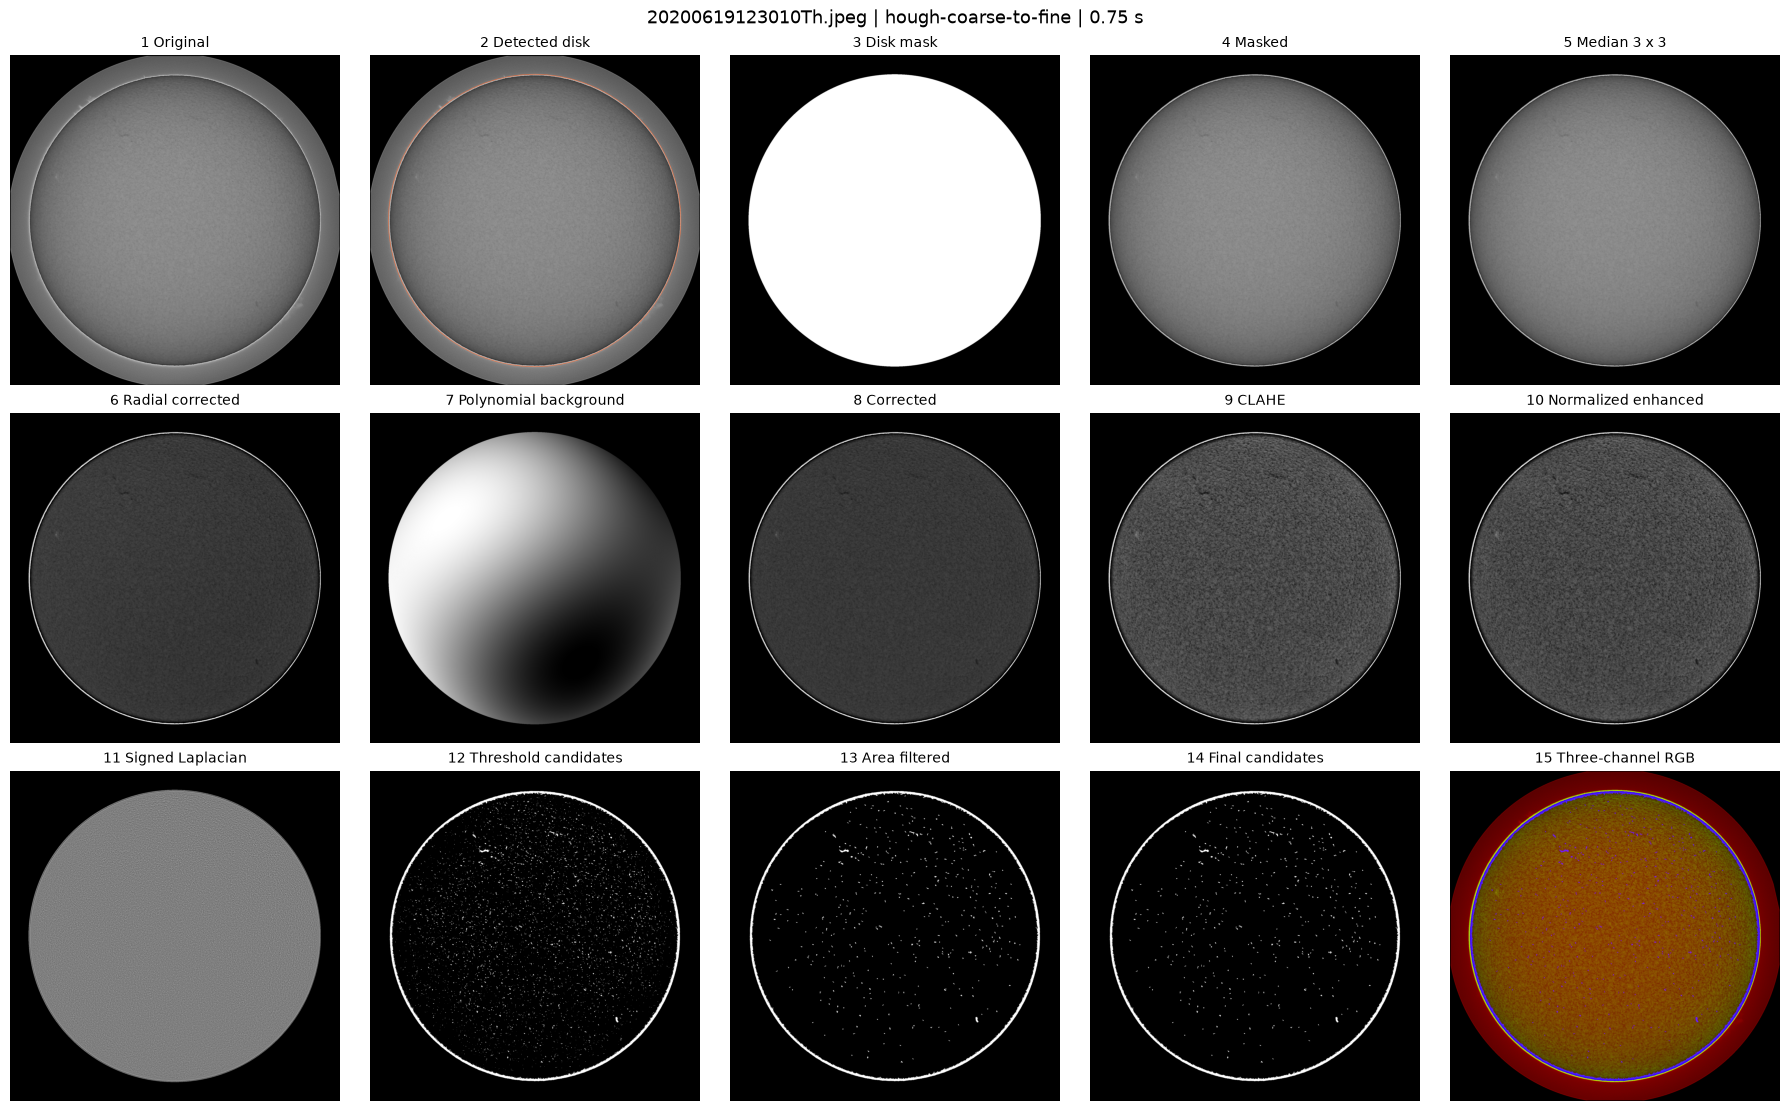

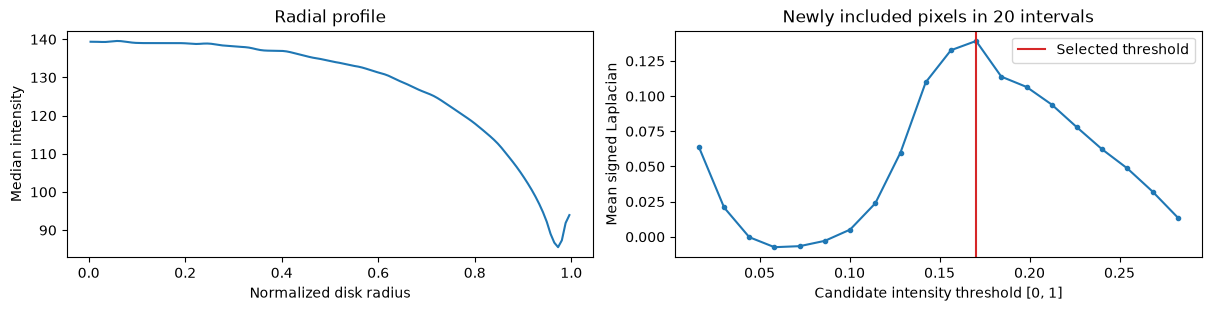

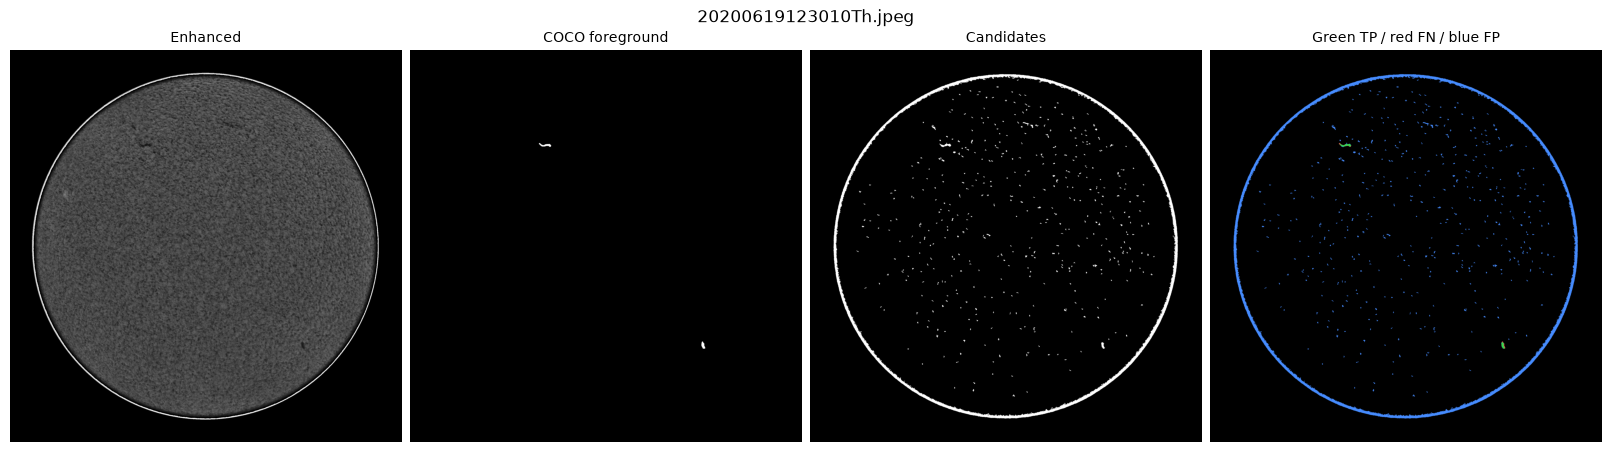

Reviewing training images:  17%|█▋        | 1/6 [00:11<00:57, 11.58s/it]

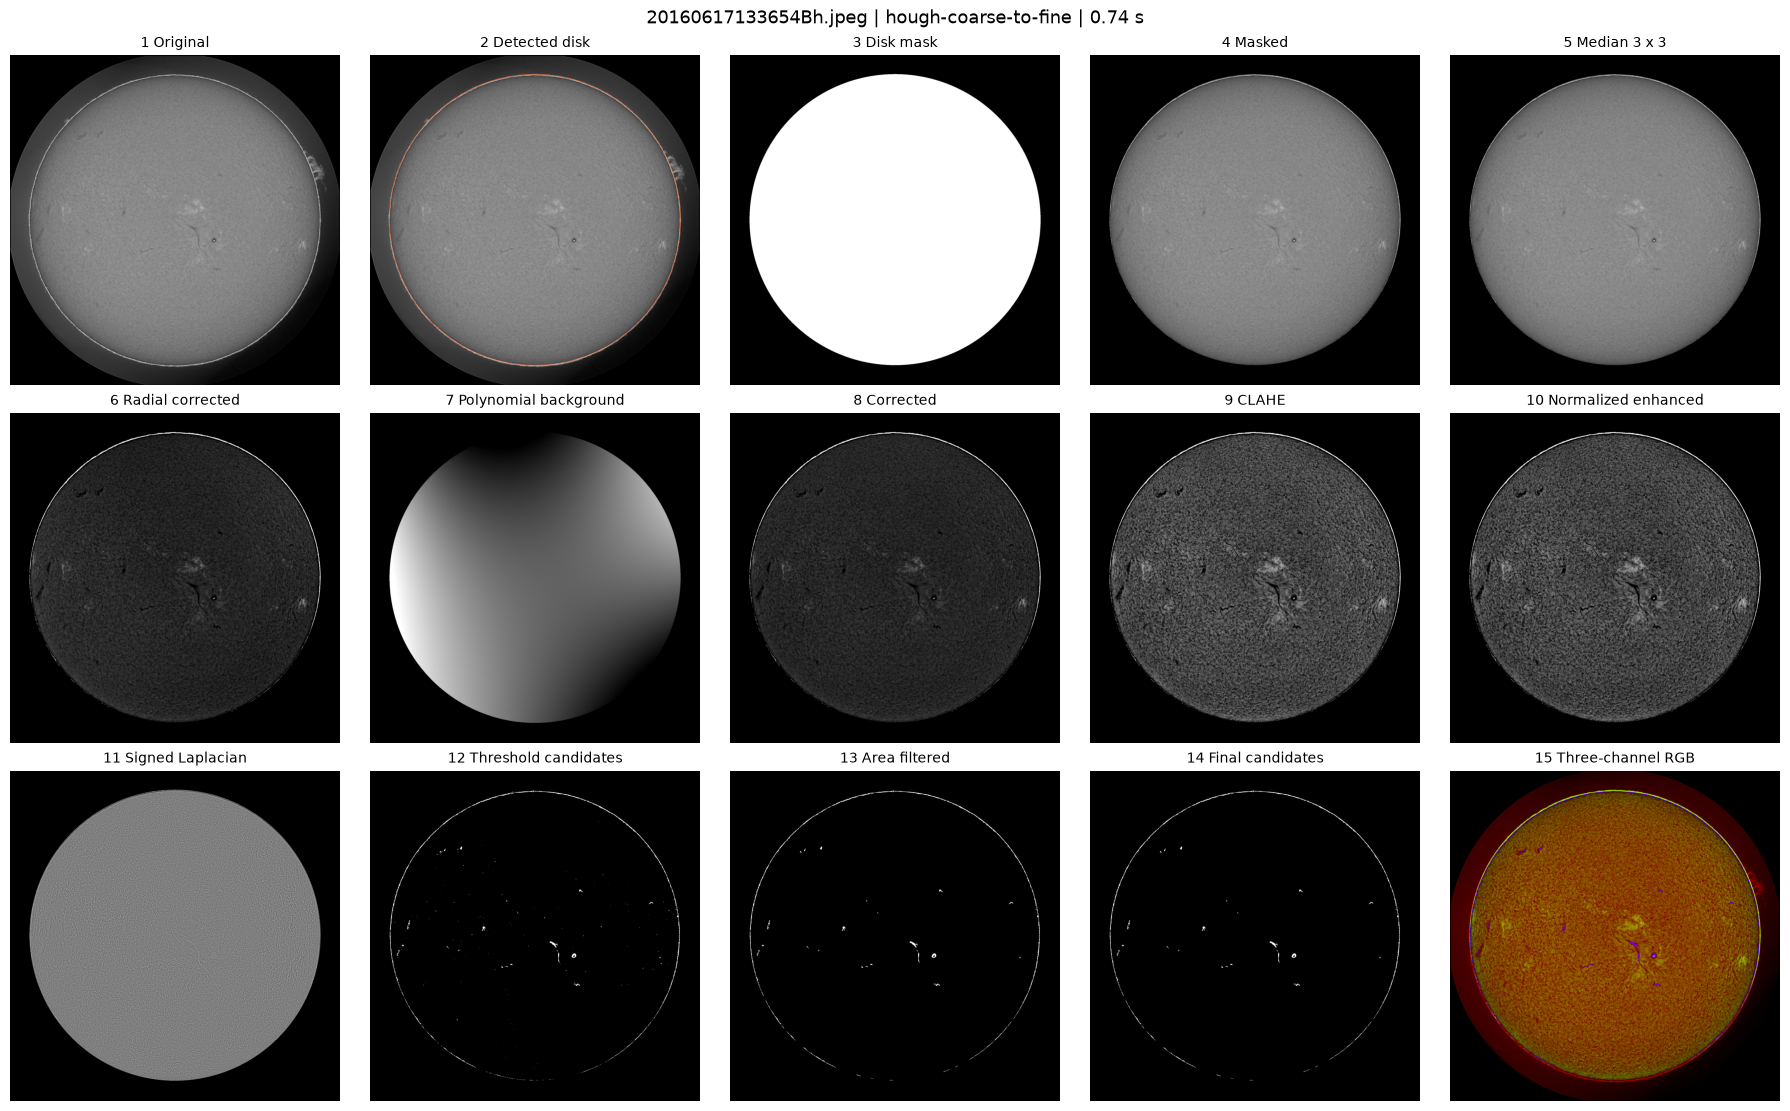

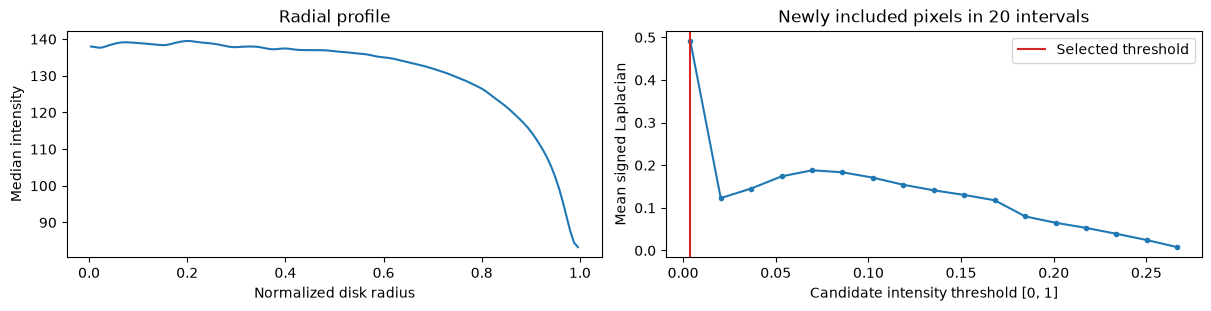

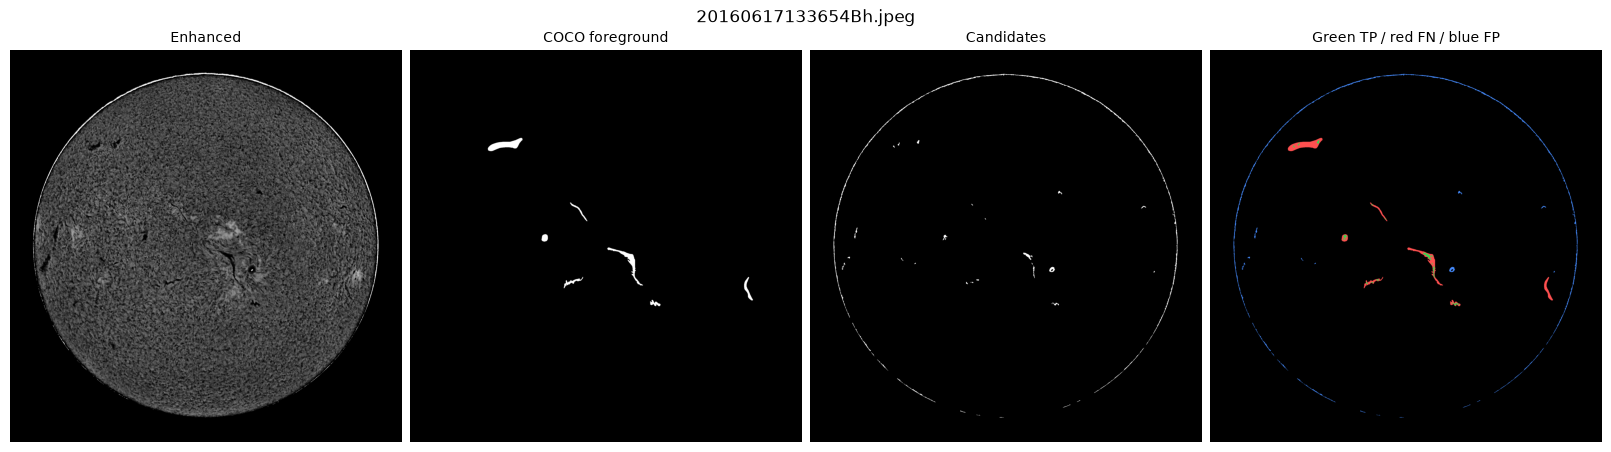

Reviewing training images:  33%|███▎      | 2/6 [00:23<00:47, 11.81s/it]

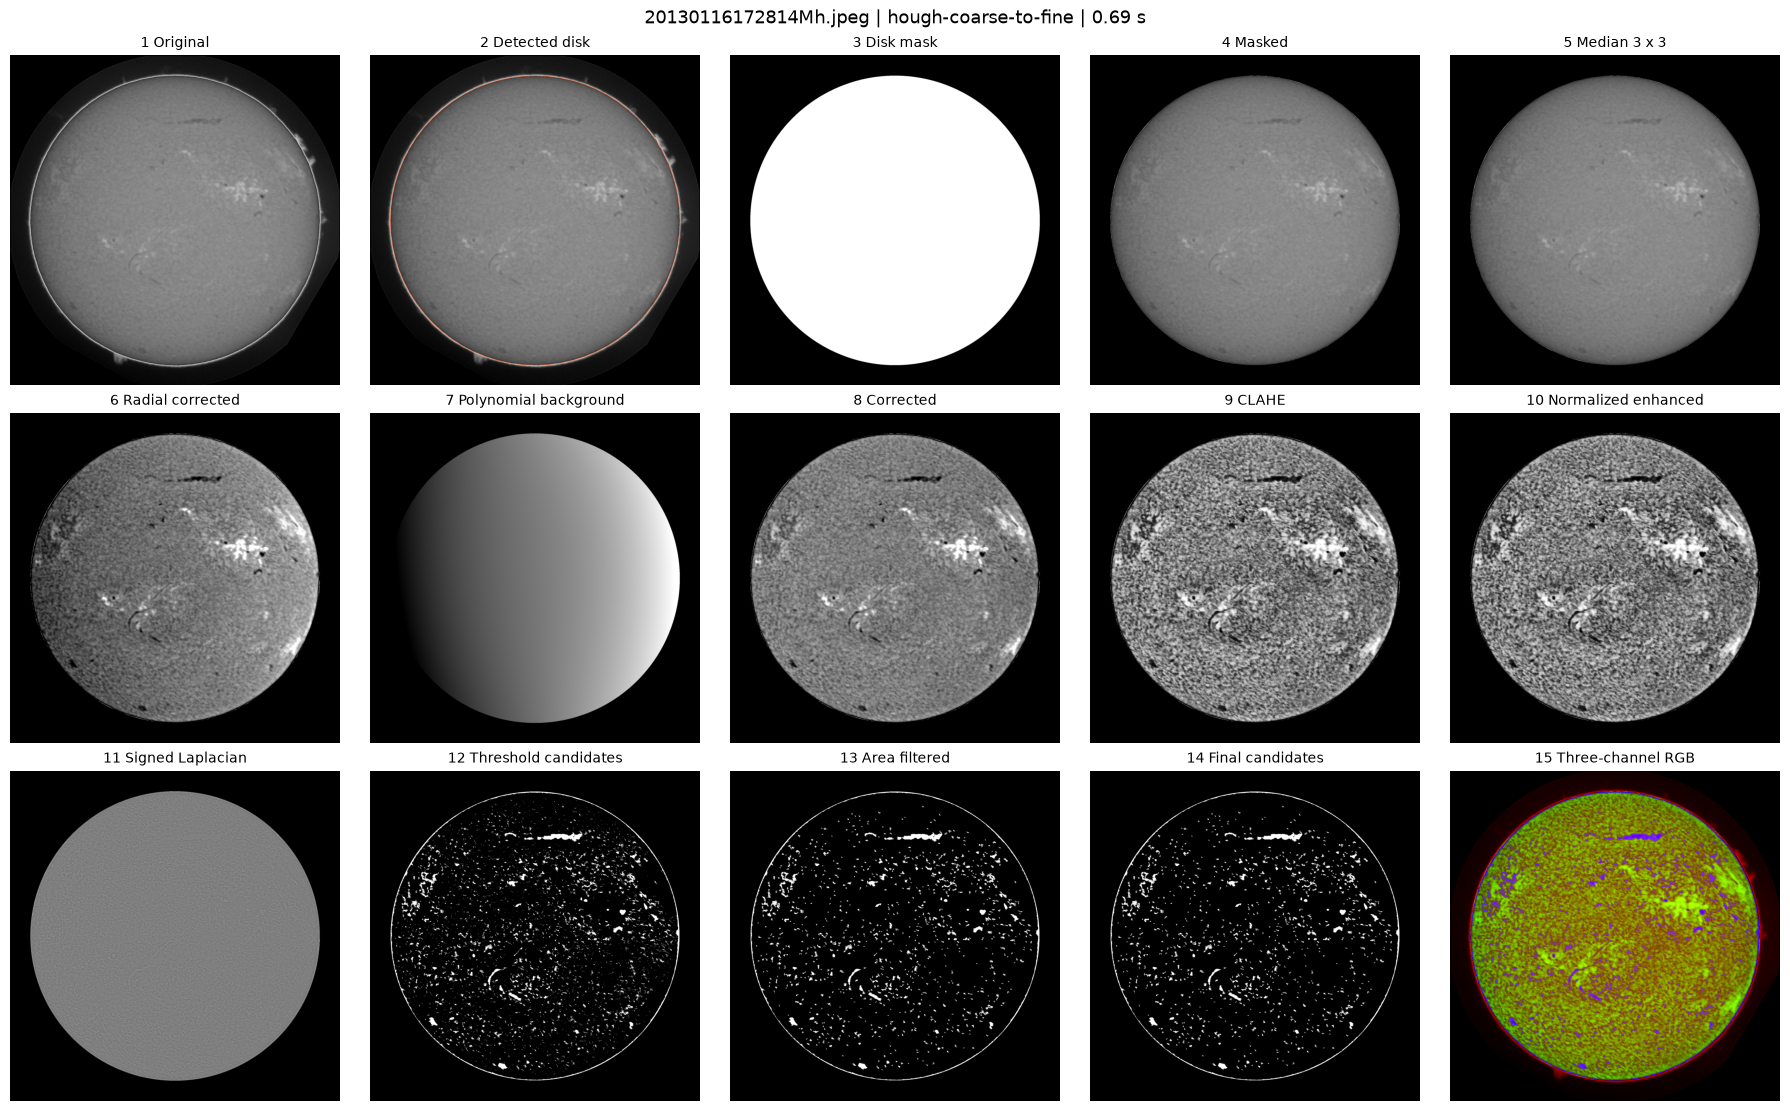

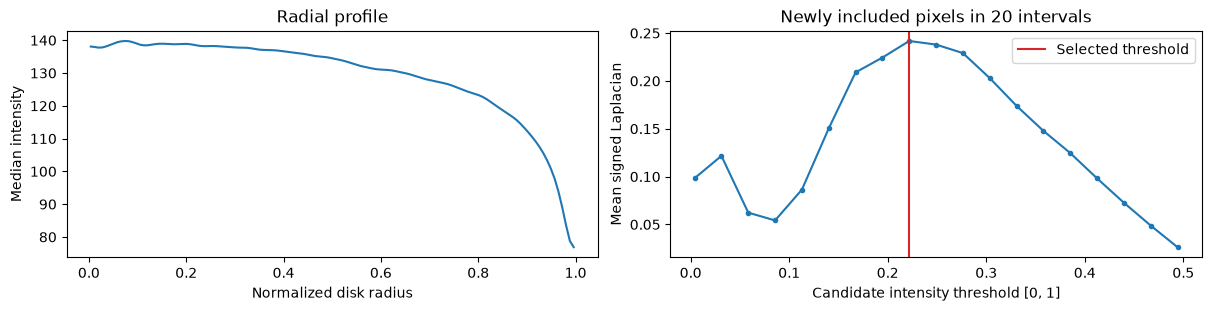

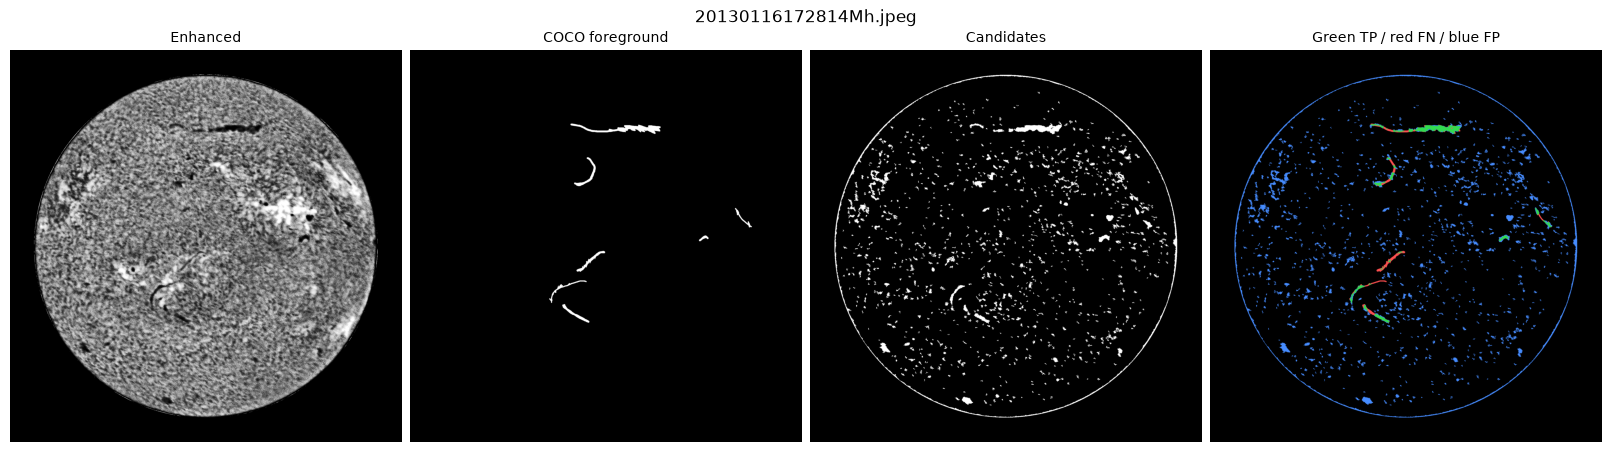

Reviewing training images:  50%|█████     | 3/6 [00:34<00:33, 11.26s/it]

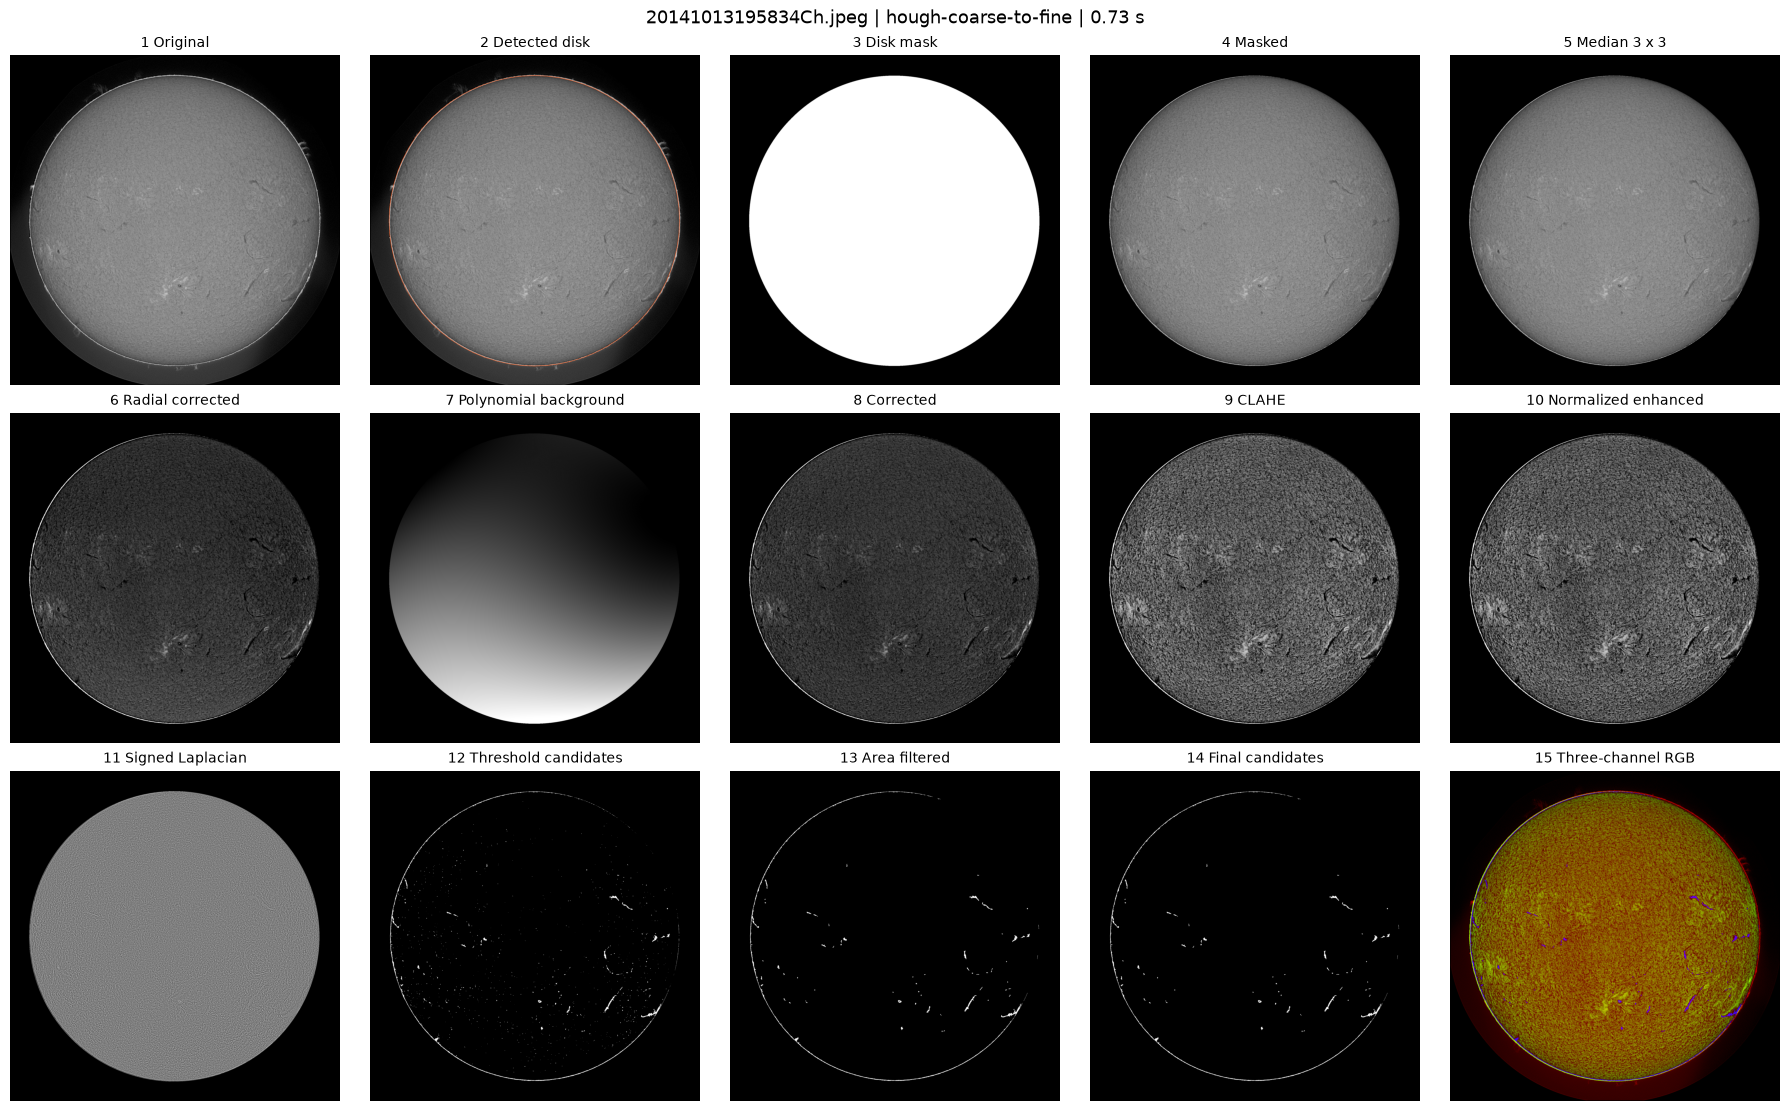

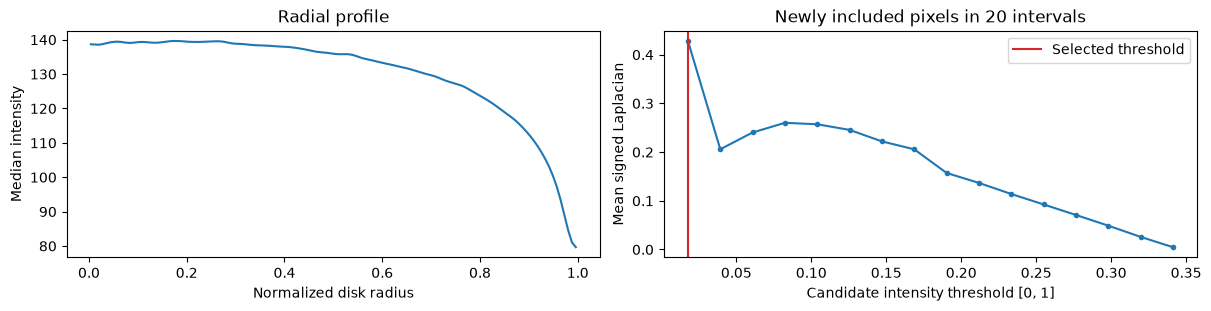

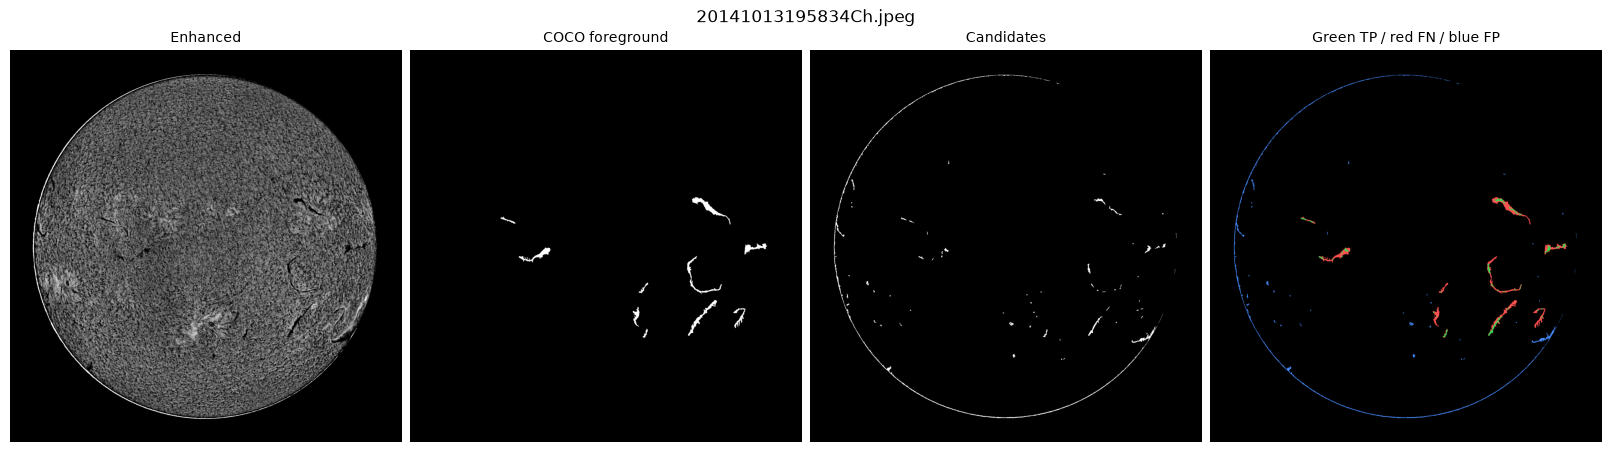

Reviewing training images:  67%|██████▋   | 4/6 [00:45<00:22, 11.17s/it]

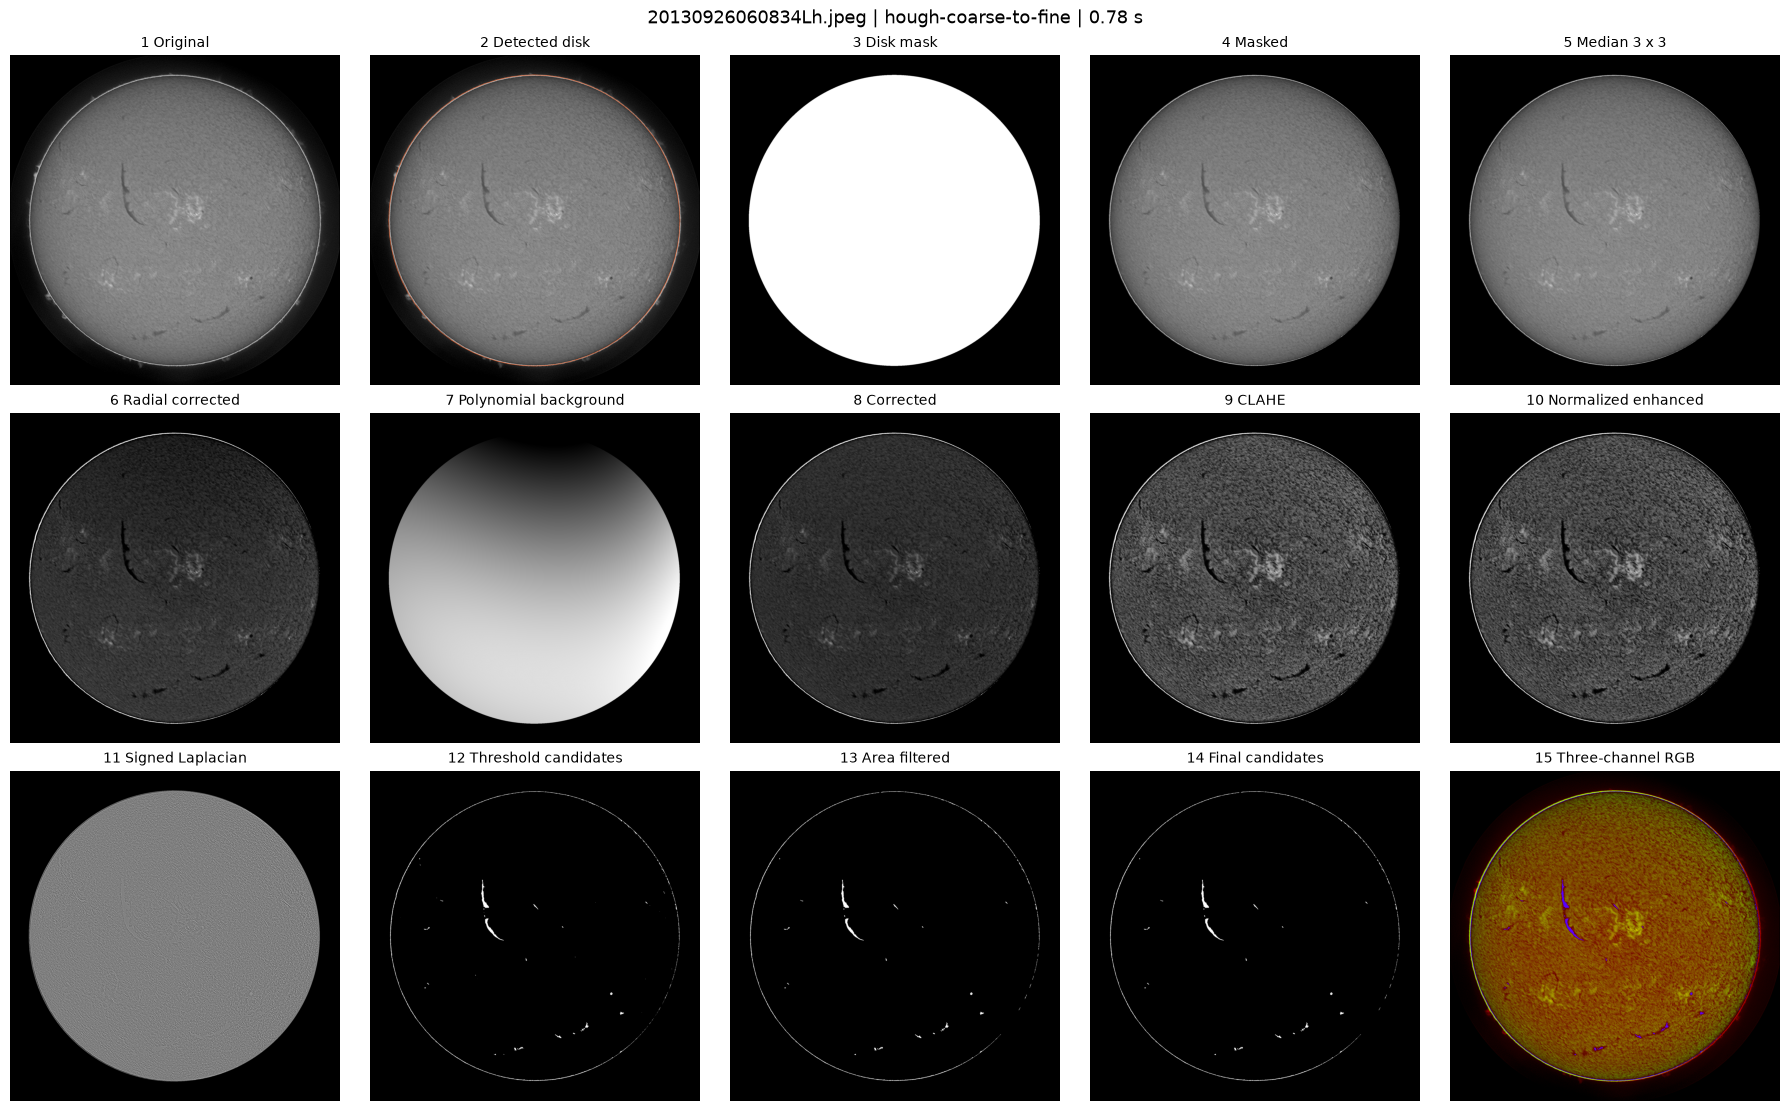

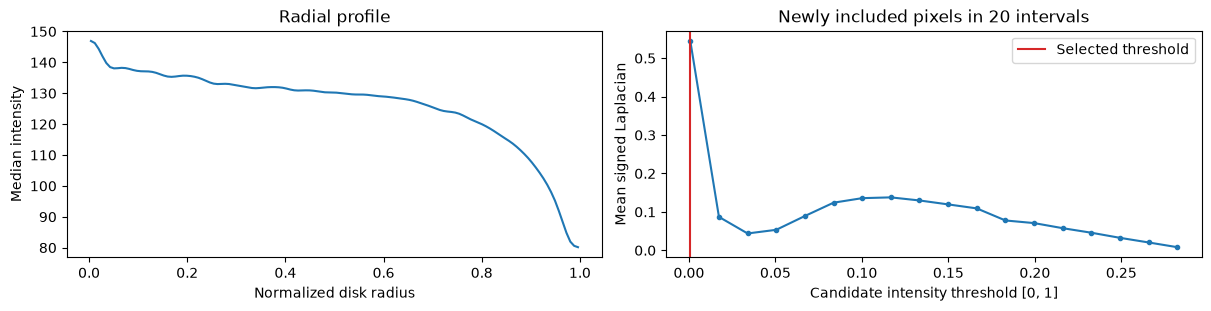

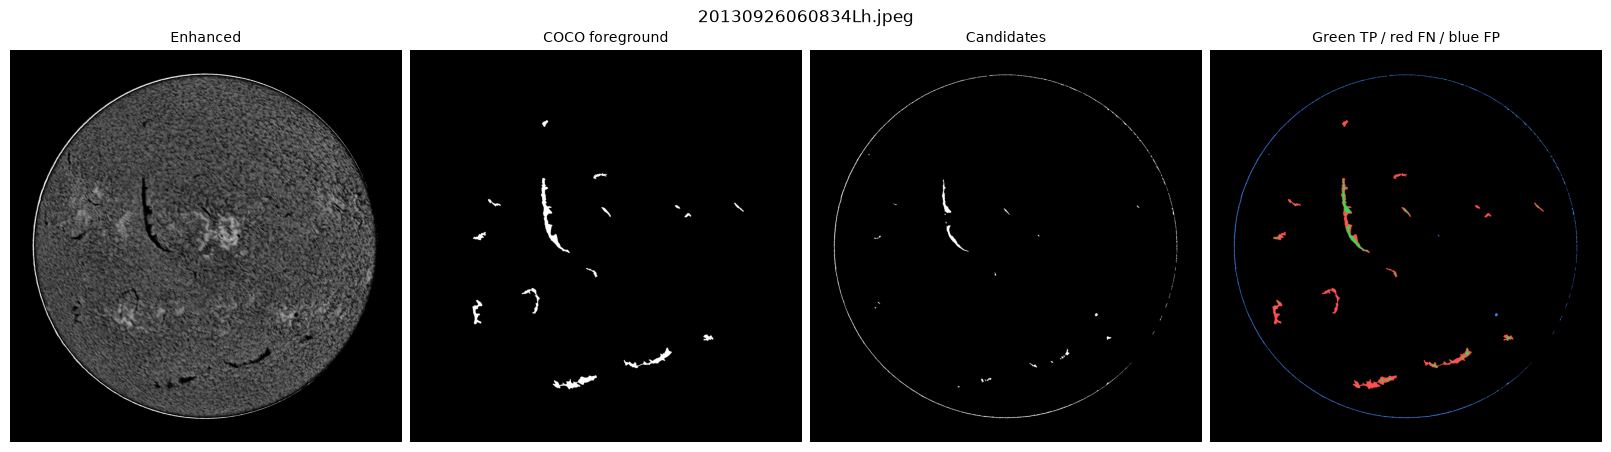

Reviewing training images:  83%|████████▎ | 5/6 [00:56<00:11, 11.34s/it]

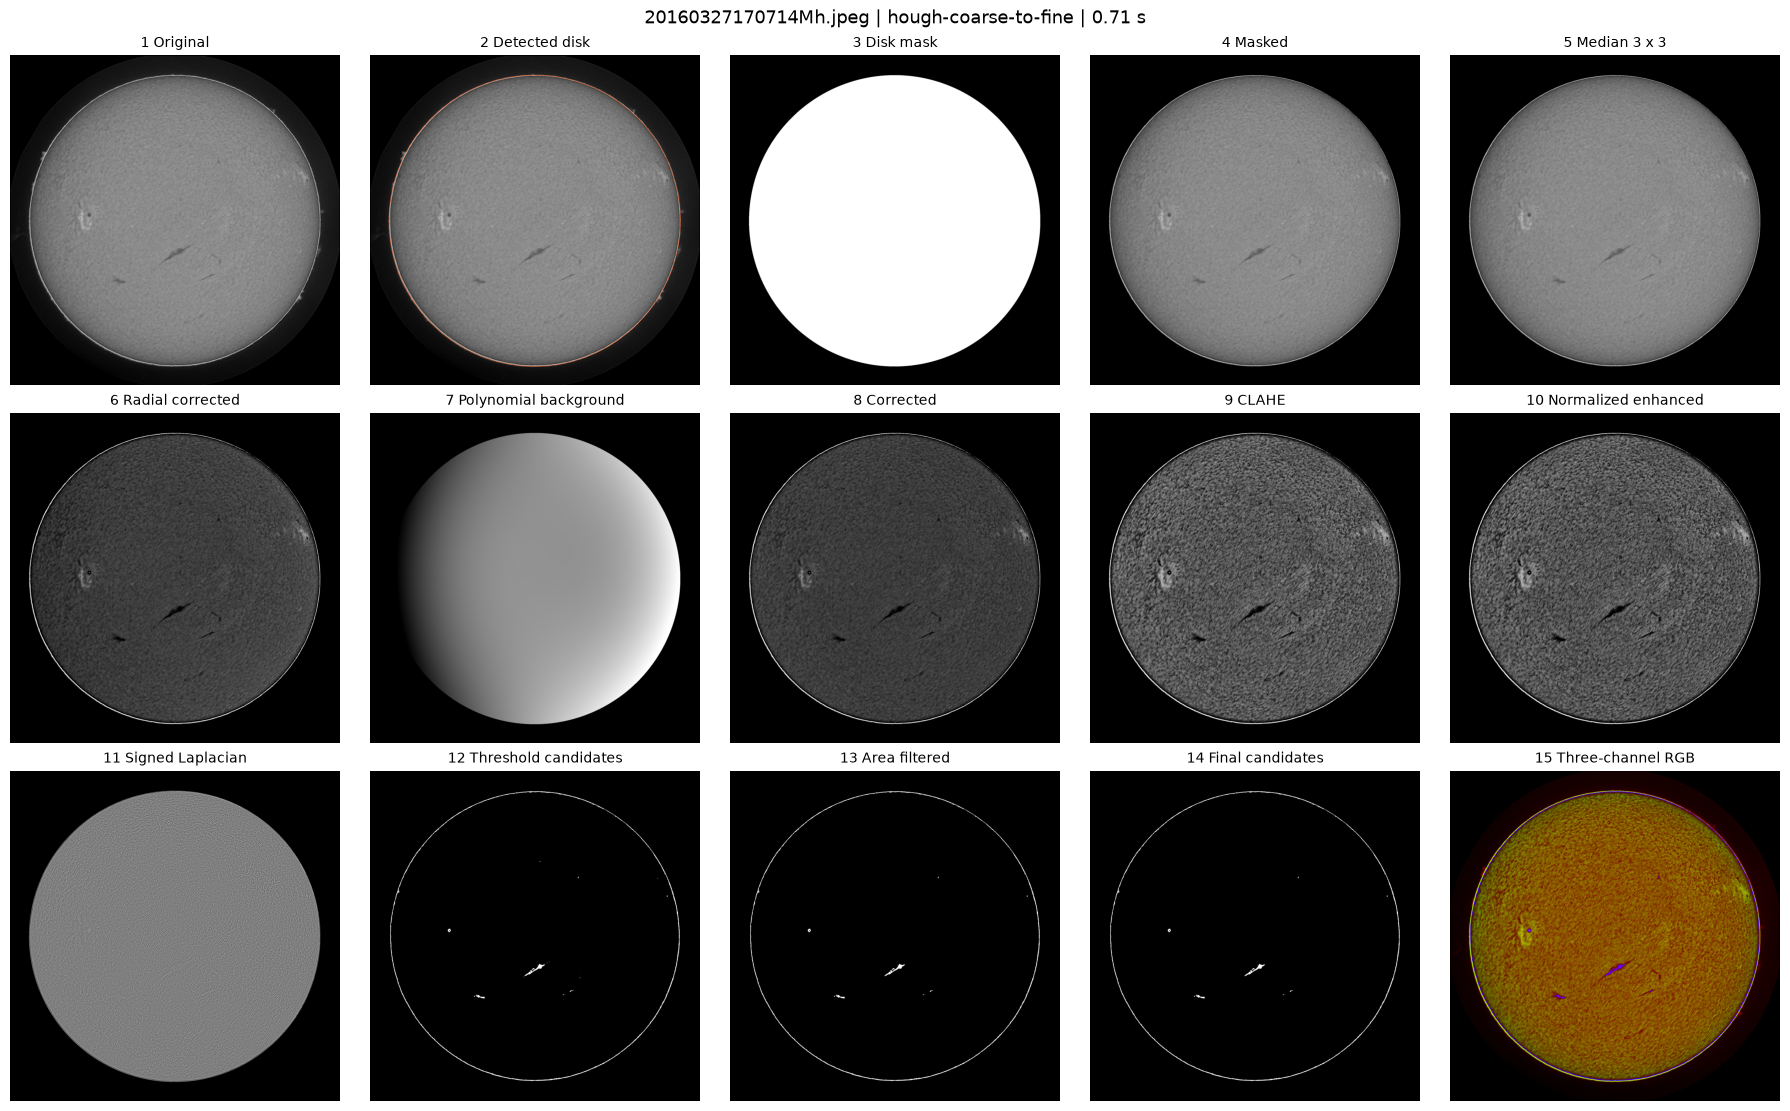

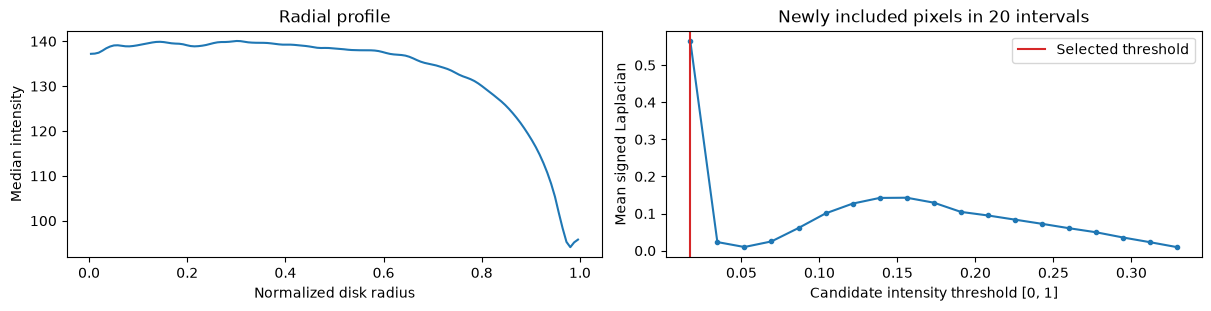

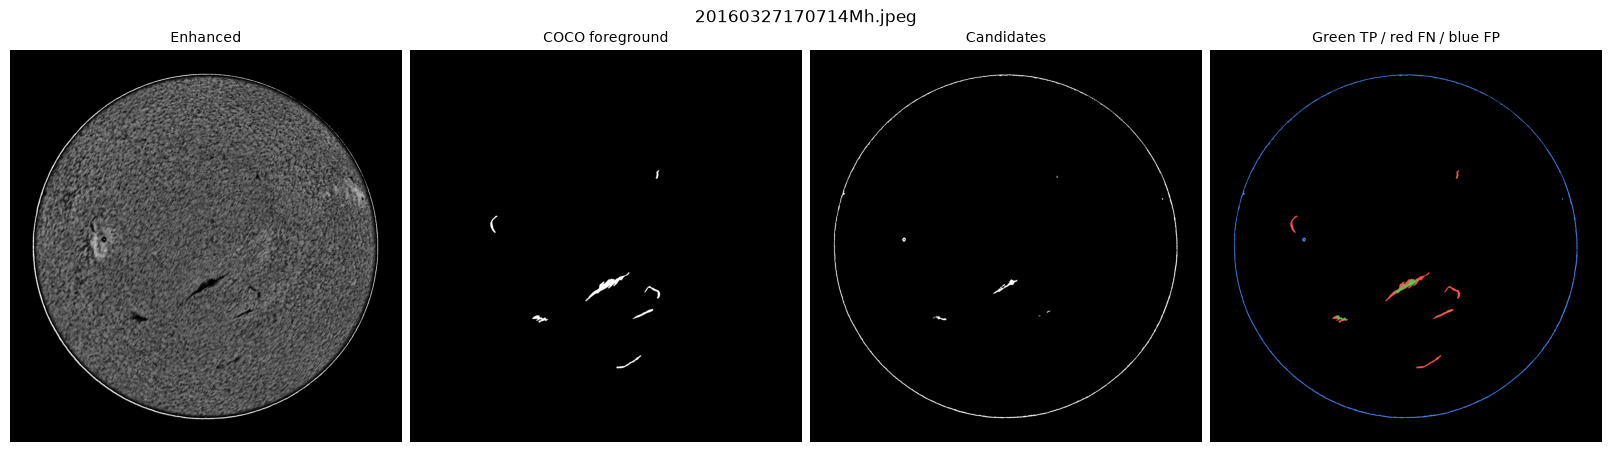

Reviewing training images: 100%|██████████| 6/6 [01:07<00:00, 11.31s/it]


,source,split,candidate_precision,candidate_recall,iou,dice,gt_instances,candidate_components,split_gt_instances,merged_components,component_pq_diagnostic,preprocessing_seconds
0,train/train_images/20200619123010Th.jpeg,train,0.008505,0.794224,0.008486,0.016829,2,430,0,0,0.006737,0.752769
1,train/train_images/20160617133654Bh.jpeg,train,0.095811,0.121472,0.056595,0.107126,17,46,0,3,0.000000,0.737135
2,train/train_images/20130116172814Mh.jpeg,train,0.087833,0.648748,0.083846,0.154719,7,969,3,0,0.002336,0.691025
3,train/train_images/20141013195834Ch.jpeg,train,0.197755,0.221831,0.116758,0.209102,18,72,4,7,0.014898,0.733738
4,train/train_images/20130926060834Lh.jpeg,train,0.295907,0.202436,0.136625,0.240405,15,55,1,0,0.000000,0.780233
5,train/train_images/20160327170714Mh.jpeg,train,0.084724,0.213128,0.064537,0.121248,7,10,0,0,0.000000,0.710762


,candidate_precision,candidate_recall,iou,dice,mean_preprocessing_seconds
0,0.085115,0.288411,0.070343,0.131439,0.734277


Preview cache: D:\filament-segmentation-2026\Final\processed_images\solar_preprocessed\preview


In [40]:
preview_records, selection_errors = select_preview_records(
    records, INPUT_DIR, PREVIEW_COUNT
)
preview_root = OUTPUT_DIR / "preview"
save_run_config(
    preview_root / "preprocessing_config.json", CONFIG, manifest, ANNOTATION_PATH
)
preview_metrics, preview_errors, preview_successes = [], list(selection_errors), []
for record in tqdm(preview_records, desc="Reviewing training images"):
    try:
        image = load_grayscale(
            INPUT_DIR / record["source"], CONFIG, record["coco_shape"]
        )
        result = preprocess_image(image, CONFIG)
        show_stages(record, result, CONFIG)
        metrics, truth = evaluate_candidates(record, result, annotations_by_image)
        show_ground_truth_comparison(record, result, truth)
        save_processed(
            record,
            result,
            preview_root,
            CONFIG,
            file_sha256(INPUT_DIR / record["source"]),
        )
        preview_metrics.append(metrics)
        preview_successes.append(record)
        del result, truth, image
    except Exception as exc:
        preview_errors.append(
            {"source": record["source"], "error": f"{type(exc).__name__}: {exc}"}
        )

export_coco_subset(COCO, preview_successes, preview_root / "train" / "annotations.json")
write_json(preview_root / "export_errors.json", preview_errors)
write_json(preview_root / "image_manifest.json", preview_successes)
write_json(preview_root / "candidate_metrics.json", preview_metrics)
if preview_errors:
    display(pd.DataFrame(preview_errors))
if not preview_metrics:
    raise RuntimeError(
        "All previews failed; inspect preview/export_errors.json before continuing."
    )

preview_table = pd.DataFrame(preview_metrics)
preview_table.to_csv(preview_root / "candidate_metrics.csv", index=False)
display(preview_table.drop(columns=["tp", "fp", "fn"]))
totals = preview_table[["tp", "fp", "fn"]].sum()
aggregate = pixel_metrics(int(totals.tp), int(totals.fp), int(totals.fn))
aggregate["mean_preprocessing_seconds"] = float(
    preview_table.preprocessing_seconds.mean()
)
write_json(preview_root / "candidate_metrics_aggregate.json", aggregate)
display(pd.DataFrame([aggregate]))
print("Preview cache:", preview_root)

## 10. Cache the chosen full splits with parallel CPU workers

Set `RUN_FULL_EXPORT = True` in the settings cell and rerun from there when the
preview is satisfactory. Add `"test"` to `EXPORT_SPLITS` only after choosing the
fixed preprocessing settings. This runs the same function for every split and
does not consult annotations for preprocessing. Existing matching caches are reused.
Lossless float intermediates can require substantial disk space; disable
`save_float_stages` after inspection if only model inputs and PNG diagnostics are needed.
The summary distinguishes preprocessing time from total export time.


In [41]:
if RUN_FULL_EXPORT:
    save_run_config(
        OUTPUT_DIR / "preprocessing_config.json", CONFIG, manifest, ANNOTATION_PATH
    )
    export_results, export_errors = export_dataset(
        records, INPUT_DIR, OUTPUT_DIR, CONFIG, COCO, EXPORT_SPLITS, WORKERS
    )
    if export_results:
        export_table = pd.DataFrame(export_results)
        display(
            export_table.groupby(["split", "status"])
            .agg(
                images=("source", "count"),
                mean_preprocessing_seconds=("preprocessing_seconds", "mean"),
                mean_total_seconds=("total_seconds", "mean"),
            )
            .reset_index()
        )
    if export_errors:
        raise RuntimeError(
            f"{len(export_errors)} images failed. Inspect export_errors.json and rerun."
        )
else:
    print("Preview complete. Set RUN_FULL_EXPORT=True to cache", EXPORT_SPLITS)

Preprocessing/export: 100%|██████████| 707/707 [11:52<00:00,  1.01s/it]


Cached 707/707 images; 0 errors.


,split,status,images,mean_preprocessing_seconds,mean_total_seconds
0,train,processed,562,1.571906,8.049137
1,val,processed,145,1.545372,7.968829


## 11. Compare model inputs in controlled training experiments

Use `split_manifest.json` for all three experiments, with the same architecture,
epochs, augmentations, optimizer, and random seeds. Input A reads `original/`, B
reads `enhanced/`, and C reads `multi_channel/`. Grayscale U-Net needs one input
channel; C needs three. YOLO may read these RGB-format PNGs directly, but RGB color
augmentation is not physically meaningful for these feature channels: disable HSV,
channel swaps, and other color-specific transforms. Geometric augmentation must
apply the same transformation to every image channel and its instance masks.

Train models separately in the training notebook and record **validation model PQ**,
IoU/Dice, split/merge errors, runtime, and settings here. No model is trained by this
preprocessing notebook. Candidate component PQ above is not a substitute for
competition instance PQ. The multi-channel configuration is a hypothesis to test;
use held-out results to choose it. Never tune with test labels or fit dataset-wide
statistics on validation/test images. Apply any model-input resizing only in the
model's data loader, with corresponding mask transforms.


In [44]:
experiment_template = pd.DataFrame(
    [
        {
            "configuration": "A - baseline",
            "input_directory": "original",
            "channels": 1,
            "validation_model_PQ": np.nan,
            "validation_IoU": np.nan,
            "validation_Dice": np.nan,
            "split_errors": np.nan,
            "merge_errors": np.nan,
        },
        {
            "configuration": "B - enhanced",
            "input_directory": "enhanced",
            "channels": 1,
            "validation_model_PQ": np.nan,
            "validation_IoU": np.nan,
            "validation_Dice": np.nan,
            "split_errors": np.nan,
            "merge_errors": np.nan,
        },
        {
            "configuration": "C - three-channel",
            "input_directory": "multi_channel",
            "channels": 3,
            "validation_model_PQ": np.nan,
            "validation_IoU": np.nan,
            "validation_Dice": np.nan,
            "split_errors": np.nan,
            "merge_errors": np.nan,
        },
    ]
)
display(experiment_template)
# Saved once so rerunning preprocessing does not overwrite manually recorded scores.
experiment_path = OUTPUT_DIR / "model_comparison.csv"
if not experiment_path.exists():
    experiment_template.to_csv(experiment_path, index=False)

,configuration,input_directory,channels,validation_model_PQ,validation_IoU,validation_Dice,split_errors,merge_errors
0,A - baseline,original,1,NaN,NaN,NaN,NaN,NaN
1,B - enhanced,enhanced,1,NaN,NaN,NaN,NaN,NaN
2,C - three-channel,multi_channel,3,NaN,NaN,NaN,NaN,NaN
